# Day 2: Supervised learning on housing affordability

**Group 8** · IAAC MaAI 2026–27 · AI Methods · Day 2

Builds on the Day 1 output `data/housing_affordability_model_ready.csv` (1,210 rows × 29 columns, one row = one country in one year, 1977–2024).

**Task:** predict **next year's affordability** (`affordability_next`) for a country, from what is known this year.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# works whether the notebook is run from the repo root or from notebook/
csv_name = "housing_affordability_model_ready.csv"
data_dir = Path("data") if (Path("data") / csv_name).exists() else Path("../data")
df = pd.read_csv(data_dir / csv_name)
print(df.shape)
df.head()

(1210, 29)


,affordability_next,iso,year,decade,affordability,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,real_income_change_pct,affordability_lag1,...,region_Africa,region_Asia,region_Central/Eastern Europe,region_Latin America,region_Middle East,region_Nordic,region_North America,region_Oceania,region_Southern Europe,region_Western Europe
0,38.061170,AUS,1977,1970,39.048834,21.43,54.88,-1.016166,-0.290698,39.335029,...,0,0,0,0,0,0,0,1,0,0
1,38.880944,AUS,1978,1970,38.061170,21.28,55.91,-0.699953,1.876822,39.048834,...,0,0,0,0,0,0,0,1,0,0
2,42.938456,AUS,1979,1970,38.880944,21.75,55.94,2.208647,0.053658,38.061170,...,0,0,0,0,0,0,0,1,0,0
3,44.351318,AUS,1980,1980,42.938456,24.14,56.22,10.988506,0.500536,38.880944,...,0,0,0,0,0,0,0,1,0,0
4,41.449879,AUS,1981,1980,44.351318,25.40,57.27,5.219553,1.867663,42.938456,...,0,0,0,0,0,0,0,1,0,0


# 1. Core concepts

## 1.1 Train / test split

A model evaluated on the data it learned from looks great, because it may simply have **memorised** the answers. We can only measure learning on rows it has **not seen**. So before anything else we **split** the data:

- **Training set** (~80%): the model learns from it.
- **Test set** (~20%): locked away and used **once, at the very end**, to estimate performance on new data.

**Why we do not shuffle.** `train_test_split` shuffles rows randomly. For our data that would be a form of leakage (see README §8.2): neighbouring years of the same country are almost identical, so training on 2014 and 2016 and testing on 2015 lets the model "see the future". Our real use case is forecasting, so we split **by time**:

- **Train:** 1977–2014
- **Test:** 2015–2024 (10 years × 26 countries = 260 rows, ≈ 21%)

The cut is on a year boundary, so all 26 countries of a given year are always on the same side. **We keep this split for the whole notebook.**

### Target: log10 of next year's affordability

`affordability_next` is strongly right-skewed: most values are around 100, but South Korea in the late 1970s–early 1980s reaches above 550 (skewness ≈ 5.4). On a log scale the distribution is much closer to a bell curve (skewness ≈ 0.9), so we predict **`log10(affordability_next)`**. A prediction is turned back into an affordability value with `10 ** y_pred`.

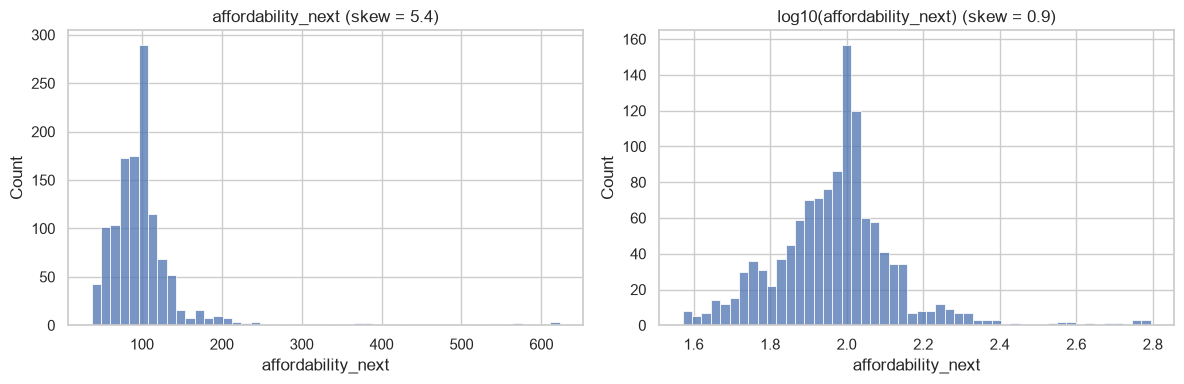

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["affordability_next"], bins=50, ax=axes[0])
axes[0].set_title(f"affordability_next (skew = {df['affordability_next'].skew():.1f})")
sns.histplot(np.log10(df["affordability_next"]), bins=50, ax=axes[1])
axes[1].set_title(f"log10(affordability_next) (skew = {np.log10(df['affordability_next']).skew():.1f})")
plt.tight_layout()
plt.show()

### Inputs: remove what must not be used

We drop from the inputs:
- `affordability_next`: the **target** itself (using it as an input would be the ultimate leak).
- `iso`: a country **identifier**, not a measurement (text, and it would let the model memorise countries).
- `data_reliable`, `is_latest_year`: **constant** in the model-ready file (always 1 and 0 after Day 1 filtering), so they carry no information.

The two leaking features from Day 1 (`affordability_vs_own_avg`, `affordability_position`) were already removed from this file. More on leakage in 1.5.

In [3]:
TARGET = "affordability_next"
drop_cols = [TARGET, "iso", "data_reliable", "is_latest_year"]

X = df.drop(columns=drop_cols)
y = np.log10(df[TARGET])

# time-based split: train up to 2014, test from 2015
SPLIT_YEAR = 2015
is_train = df["year"] < SPLIT_YEAR

X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

print(f"Features: {X.shape[1]}")
print(f"Train: {len(X_train)} rows ({len(X_train) / len(X):.0%}), years {df.loc[is_train, 'year'].min()}–{df.loc[is_train, 'year'].max()}")
print(f"Test:  {len(X_test)} rows ({len(X_test) / len(X):.0%}), years {df.loc[~is_train, 'year'].min()}–{df.loc[~is_train, 'year'].max()}")

Features: 25
Train: 950 rows (79%), years 1977–2014
Test:  260 rows (21%), years 2015–2024


In [4]:
# sanity checks: no overlap in time, every country in both sets
assert df.loc[is_train, "year"].max() < df.loc[~is_train, "year"].min()
assert set(df.loc[is_train, "iso"]) == set(df.loc[~is_train, "iso"])
X.columns.tolist()

['year',
 'decade',
 'affordability',
 'real_house_price_index',
 'real_personal_disposable_income',
 'real_hpi_change_pct',
 'real_income_change_pct',
 'affordability_lag1',
 'affordability_lag2',
 'affordability_3yr_avg',
 'nominal_zero',
 'hyperinflation_country',
 'price_shock_up',
 'price_shock_down',
 'gfc_period',
 'region_Africa',
 'region_Asia',
 'region_Central/Eastern Europe',
 'region_Latin America',
 'region_Middle East',
 'region_Nordic',
 'region_North America',
 'region_Oceania',
 'region_Southern Europe',
 'region_Western Europe']

## 1.2 Underfitting and overfitting

A model can fail in two opposite ways:

| | **Underfitting** | **Good fit** | **Overfitting** |
|---|---|---|---|
| What happens | The model is too **simple** to capture the pattern | Captures the pattern, ignores the noise | The model is too **complex**: it memorises the noise |
| Training error | High | Low | **Very low** |
| Test error | High | Low | **High** |
| Analogy | A student who only learned "the answer is usually C" | A student who understood the subject | A student who memorised last year's exam |

### Synthetic example: window-to-wall ratio vs energy demand

We invent a "true" relation between the **window-to-wall ratio** (WWR) of a façade and its **energy demand**: too few windows means more artificial lighting, too many means more heat loss and overheating, so the curve is U-shaped with an optimum around 35%. We add random noise (like measurement errors), then fit three polynomial curves of increasing complexity on the training points (dark) and check them on the test points (orange).

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

rng = np.random.default_rng(42)

def true_demand(wwr):
    # kWh/m²/year: minimum around 35% WWR
    return 90 + 400 * (wwr - 0.35) ** 2

wwr = rng.uniform(0.05, 0.90, 40)
demand = true_demand(wwr) + rng.normal(0, 8, wwr.size)

# synthetic data has no time order, so a random split is fine here
wwr_train, wwr_test, dem_train, dem_test = train_test_split(
    wwr, demand, test_size=0.3, random_state=42)
print(len(wwr_train), "train points,", len(wwr_test), "test points")

28 train points, 12 test points


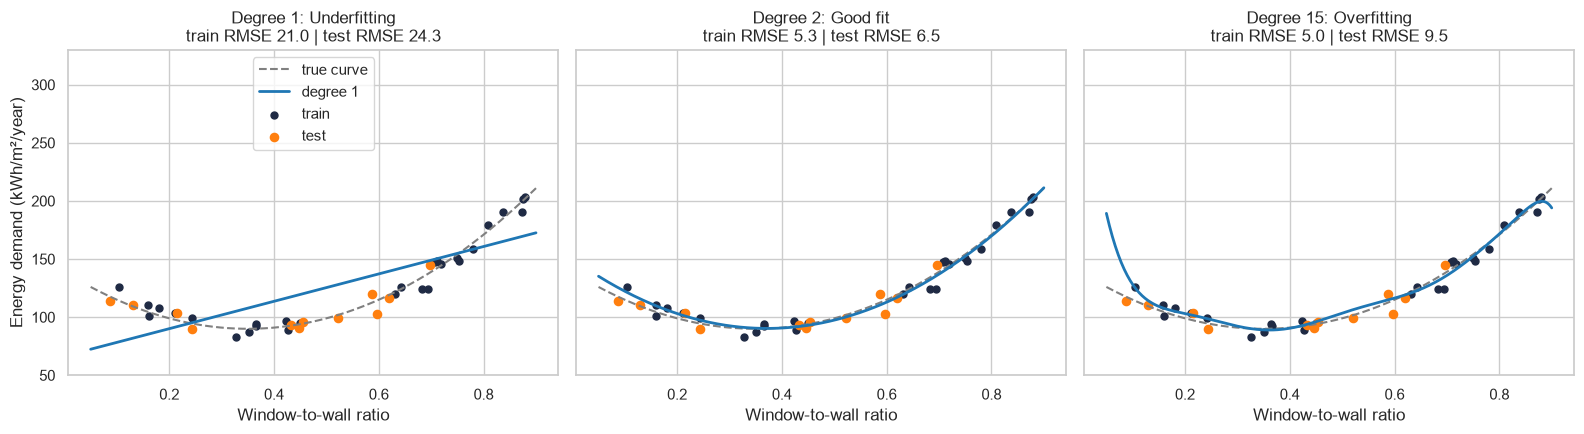

,degree,fit,train RMSE,test RMSE
0,1,Underfitting,21.0,24.3
1,2,Good fit,5.3,6.5
2,15,Overfitting,5.0,9.5


In [6]:
degrees = {1: "Underfitting", 2: "Good fit", 15: "Overfitting"}
grid = np.linspace(0.05, 0.90, 300)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
rows = []
for ax, (deg, label) in zip(axes, degrees.items()):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(wwr_train.reshape(-1, 1), dem_train)

    rmse_train = root_mean_squared_error(dem_train, model.predict(wwr_train.reshape(-1, 1)))
    rmse_test = root_mean_squared_error(dem_test, model.predict(wwr_test.reshape(-1, 1)))
    rows.append({"degree": deg, "fit": label, "train RMSE": rmse_train, "test RMSE": rmse_test})

    ax.plot(grid, true_demand(grid), "--", color="grey", label="true curve")
    ax.plot(grid, model.predict(grid.reshape(-1, 1)), color="tab:blue", linewidth=2, label=f"degree {deg}")
    ax.scatter(wwr_train, dem_train, color="#1f2a44", s=25, label="train")
    ax.scatter(wwr_test, dem_test, color="tab:orange", s=35, label="test")
    ax.set_ylim(50, 330)
    ax.set_title(f"Degree {deg}: {label}\ntrain RMSE {rmse_train:.1f} | test RMSE {rmse_test:.1f}")
    ax.set_xlabel("Window-to-wall ratio")
axes[0].set_ylabel("Energy demand (kWh/m²/year)")
axes[0].legend(loc="upper center")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).round(1)

### Error vs complexity

Training error keeps falling as the polynomial degree grows: a more flexible curve can always pass closer to the training points. Test error falls at first, then **rises again** once the model starts fitting the noise. The best model sits at the bottom of the test curve, not the training curve.

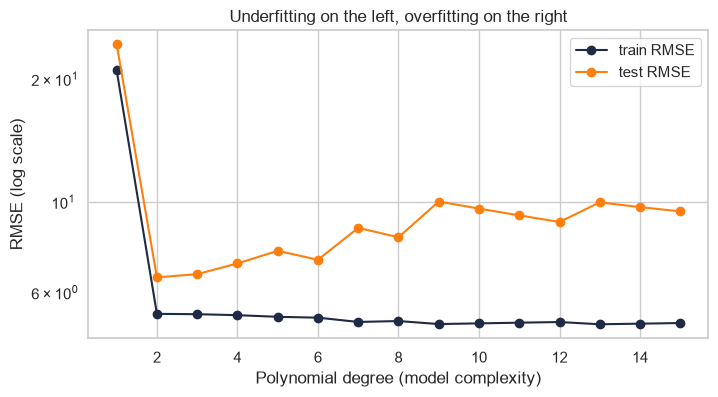

In [7]:
sweep = []
for deg in range(1, 16):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    model.fit(wwr_train.reshape(-1, 1), dem_train)
    sweep.append({
        "degree": deg,
        "train": root_mean_squared_error(dem_train, model.predict(wwr_train.reshape(-1, 1))),
        "test": root_mean_squared_error(dem_test, model.predict(wwr_test.reshape(-1, 1))),
    })
sweep = pd.DataFrame(sweep)

plt.figure(figsize=(8, 4))
plt.plot(sweep["degree"], sweep["train"], "o-", color="#1f2a44", label="train RMSE")
plt.plot(sweep["degree"], sweep["test"], "o-", color="tab:orange", label="test RMSE")
plt.yscale("log")
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("RMSE (log scale)")
plt.title("Underfitting on the left, overfitting on the right")
plt.legend()
plt.show()

### The same check on our housing data

We apply the idea to the real task using a **decision tree**, whose complexity is set by `max_depth` (how many yes/no questions it can ask in a row). We use the time-based split from 1.1. Errors are RMSE on `log10(affordability_next)`.

This is only a diagnostic: picking the depth by looking at the test set would leak it into model selection. Later we choose hyperparameters with validation data instead.

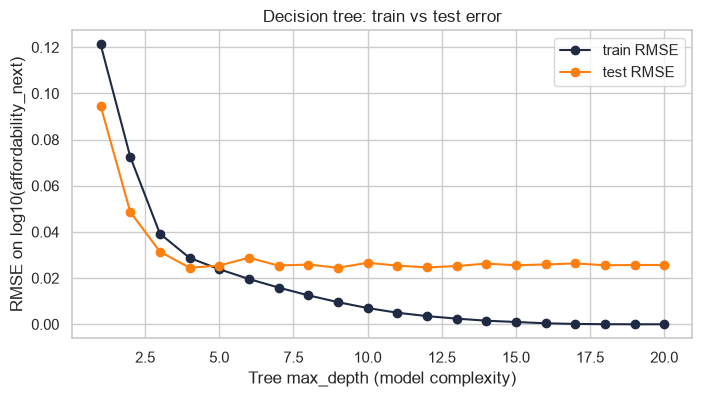

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train,0.1213,0.0726,0.0393,0.0287,0.0238,0.0196,0.0159,0.0126,0.0096,0.0070,0.0050,0.0035,0.0024,0.0015,0.0010,0.0004,0.0001,0.0000,0.0000,0.0000
test,0.0947,0.0487,0.0315,0.0245,0.0254,0.0288,0.0254,0.0259,0.0245,0.0266,0.0254,0.0246,0.0252,0.0263,0.0256,0.0259,0.0264,0.0256,0.0257,0.0257


In [8]:
from sklearn.tree import DecisionTreeRegressor

tree_sweep = []
for depth in range(1, 21):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train)
    tree_sweep.append({
        "max_depth": depth,
        "train": root_mean_squared_error(y_train, tree.predict(X_train)),
        "test": root_mean_squared_error(y_test, tree.predict(X_test)),
    })
tree_sweep = pd.DataFrame(tree_sweep)

plt.figure(figsize=(8, 4))
plt.plot(tree_sweep["max_depth"], tree_sweep["train"], "o-", color="#1f2a44", label="train RMSE")
plt.plot(tree_sweep["max_depth"], tree_sweep["test"], "o-", color="tab:orange", label="test RMSE")
plt.xlabel("Tree max_depth (model complexity)")
plt.ylabel("RMSE on log10(affordability_next)")
plt.title("Decision tree: train vs test error")
plt.legend()
plt.show()

tree_sweep.round(4).set_index("max_depth").T

### What we see

**Synthetic example**
- **Degree 1 (underfitting):** a straight line cannot follow the U-shape. Train and test errors are both high (≈ 21 and 24 kWh/m²/year).
- **Degree 2 (good fit):** follows the true curve. Train and test errors are both low and close (≈ 5 and 6.5).
- **Degree 15 (overfitting):** the lowest training error, but the test error almost doubles (≈ 9.5) and the curve shoots up at the left edge where there are few training points.

**Housing data (decision tree)**
- **Depth 1–3, underfitting:** both errors are high. Test error is even *below* training error here, because the training years include the extreme early values (e.g. South Korea 1978–83) that the test years 2015–2024 do not have.
- **Depth ≈ 4–5, good fit:** test error reaches its minimum, about 0.025 in log10, which is roughly a **6% error** on next year's affordability.
- **Depth > 5, overfitting:** training error keeps falling to **0** (the tree memorises every row by depth ~17), while test error stops improving at ≈ 0.025–0.029. The growing gap between the two curves is the sign of overfitting.

**Takeaway:** judge a model on the test error, and watch the **gap** between training and test error. A training error near zero is a warning, not a success.

The degree-15 curve has the **lowest training error** of all, yet its test error is almost **double** that of the simple degree-2 curve, because it bends to follow the noise in the training points. This is the most important lesson of the day:

> **A model is only as good as its performance on data it has never seen.**

Every model has some **complexity knob** (the polynomial degree here, the depth of a tree, the number of neighbours in KNN…). Too little → underfitting; too much → overfitting. These knobs are called **hyperparameters**, and choosing them well is part of the job (section 4.6).

## 1.3 Cross-validation

If we need data the model has not seen to compare models and choose hyperparameters, can we use the test set? **No!** If we pick the model that does best on the test set, the test set is no longer "unseen": we would be fooling ourselves. The test set is for the **final** check only.

Instead we use **K-fold cross-validation** on the training set:
1. Split the training set into K parts (*folds*), e.g. K = 5.
2. Train on 4 folds, validate on the 5th.
3. Repeat 5 times, so each fold is used once for validation.
4. Report the **average** score (and its spread).

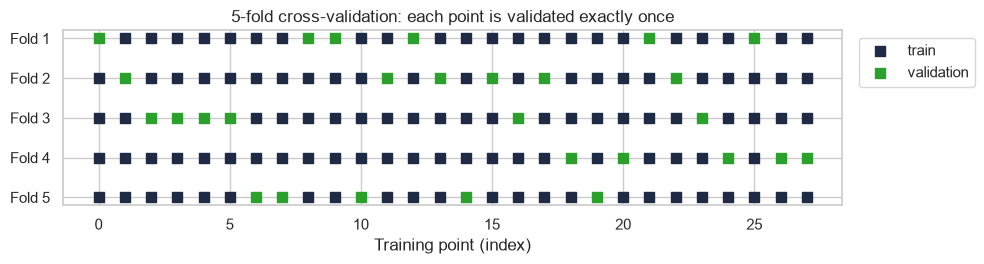

In [9]:
from sklearn.model_selection import KFold, cross_val_score

# what 5-fold cross-validation does with the 28 synthetic training points
kf = KFold(n_splits=5, shuffle=True, random_state=42)

fig, ax = plt.subplots(figsize=(10, 2.8))
for i, (tr_idx, val_idx) in enumerate(kf.split(wwr_train)):
    ax.scatter(tr_idx, [i] * len(tr_idx), marker="s", s=60, color="#1f2a44",
               label="train" if i == 0 else None)
    ax.scatter(val_idx, [i] * len(val_idx), marker="s", s=60, color="tab:green",
               label="validation" if i == 0 else None)
ax.set_yticks(range(5), [f"Fold {i + 1}" for i in range(5)])
ax.invert_yaxis()
ax.set_xlabel("Training point (index)")
ax.set_title("5-fold cross-validation: each point is validated exactly once")
ax.legend(loc="upper right", bbox_to_anchor=(1.18, 1))
plt.tight_layout()
plt.show()

### Choosing the polynomial degree with cross-validation

We now choose the degree **without touching the test set**: for each degree we run 5-fold CV on the training points and look at the average validation error. Only at the end do we compare with the test error from 1.2, to see if CV picked well.

Degree chosen by 5-fold CV: 2


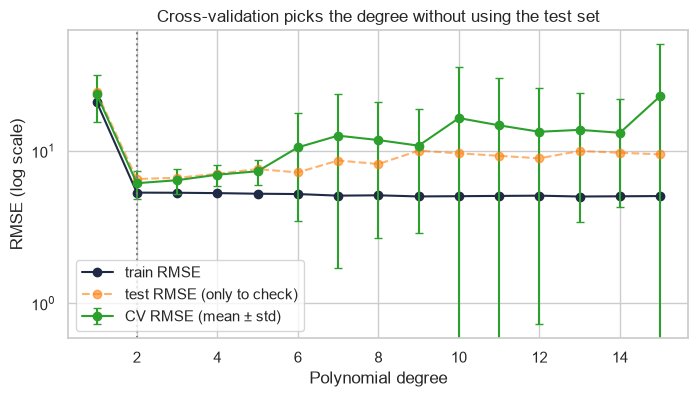

degree,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
cv_mean,23.6,6.1,6.4,7.0,7.3,10.5,12.6,11.7,10.8,16.4,14.7,13.3,13.7,13.1,22.8
cv_std,8.0,1.3,1.2,1.1,1.3,7.1,10.9,9.1,7.9,18.9,15.4,12.6,10.3,8.9,27.1
train,21.0,5.3,5.3,5.3,5.2,5.2,5.1,5.1,5.0,5.0,5.1,5.1,5.0,5.0,5.0
test,24.3,6.5,6.6,7.1,7.6,7.2,8.6,8.2,10.0,9.6,9.3,8.9,10.0,9.7,9.5


In [10]:
cv_rows = []
for deg in range(1, 16):
    model = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    # sklearn maximises scores, so errors are returned negative
    scores = -cross_val_score(model, wwr_train.reshape(-1, 1), dem_train,
                              cv=kf, scoring="neg_root_mean_squared_error")
    cv_rows.append({"degree": deg, "cv_mean": scores.mean(), "cv_std": scores.std()})
cv_poly = pd.DataFrame(cv_rows).merge(sweep, on="degree")

best_deg = int(cv_poly.loc[cv_poly["cv_mean"].idxmin(), "degree"])
print(f"Degree chosen by 5-fold CV: {best_deg}")

plt.figure(figsize=(8, 4))
plt.plot(cv_poly["degree"], cv_poly["train"], "o-", color="#1f2a44", label="train RMSE")
plt.errorbar(cv_poly["degree"], cv_poly["cv_mean"], yerr=cv_poly["cv_std"],
             fmt="o-", color="tab:green", capsize=3, label="CV RMSE (mean ± std)")
plt.plot(cv_poly["degree"], cv_poly["test"], "o--", color="tab:orange", alpha=0.6, label="test RMSE (only to check)")
plt.axvline(best_deg, color="grey", linestyle=":")
plt.yscale("log")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (log scale)")
plt.title("Cross-validation picks the degree without using the test set")
plt.legend()
plt.show()

cv_poly.round(1).set_index("degree").T

### Cross-validation on the housing data: folds must respect time

On the housing data a **shuffled** K-fold has the same problem as a random train/test split (1.1): the model validates on 1995 while having trained on 1994 *and* 1996 of the same country, which are almost identical. The score looks better than what we would get when forecasting.

So we use **time-based folds** (`TimeSeriesSplit`, an "expanding window"): split the training years 1977–2014 into consecutive blocks; each fold trains on all years **before** a block and validates on that block. Folds are cut on whole years, so all 26 countries of a year stay together.

In [11]:
from sklearn.model_selection import TimeSeriesSplit

train_years = df.loc[is_train, "year"].to_numpy()
unique_years = np.sort(np.unique(train_years))

# TimeSeriesSplit on the list of years, then map the years back to rows
time_folds = []
for tr_y, val_y in TimeSeriesSplit(n_splits=5).split(unique_years):
    tr_rows = np.where(np.isin(train_years, unique_years[tr_y]))[0]
    val_rows = np.where(np.isin(train_years, unique_years[val_y]))[0]
    time_folds.append((tr_rows, val_rows))
    print(f"train {unique_years[tr_y].min()}–{unique_years[tr_y].max()} ({len(tr_rows)} rows)"
          f"  →  validate {unique_years[val_y].min()}–{unique_years[val_y].max()} ({len(val_rows)} rows)")

train 1977–1984 (190 rows)  →  validate 1985–1990 (144 rows)
train 1977–1990 (334 rows)  →  validate 1991–1996 (148 rows)
train 1977–1996 (482 rows)  →  validate 1997–2002 (156 rows)
train 1977–2002 (638 rows)  →  validate 2003–2008 (156 rows)
train 1977–2008 (794 rows)  →  validate 2009–2014 (156 rows)


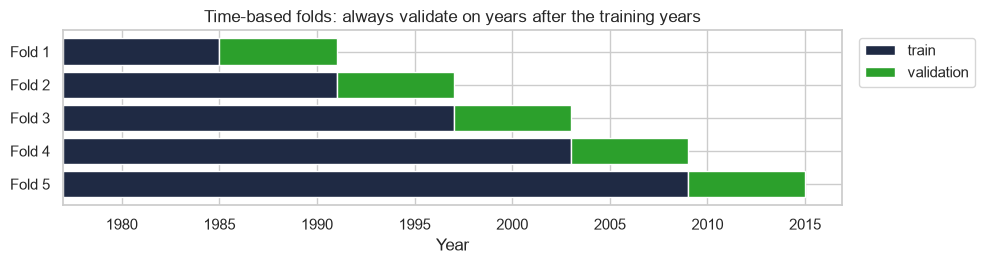

In [12]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, (tr_rows, val_rows) in enumerate(time_folds):
    ax.barh(i, np.ptp(train_years[tr_rows]) + 1, left=train_years[tr_rows].min(), color="#1f2a44",
            label="train" if i == 0 else None)
    ax.barh(i, np.ptp(train_years[val_rows]) + 1, left=train_years[val_rows].min(), color="tab:green",
            label="validation" if i == 0 else None)
ax.set_yticks(range(5), [f"Fold {i + 1}" for i in range(5)])
ax.invert_yaxis()
ax.set_xlabel("Year")
ax.set_title("Time-based folds: always validate on years after the training years")
ax.legend(loc="upper right", bbox_to_anchor=(1.18, 1))
plt.tight_layout()
plt.show()

### Choosing the tree depth with cross-validation

We repeat the decision-tree experiment from 1.2, but now choose `max_depth` from the **cross-validation** score instead of peeking at the test set. For comparison we also run a **shuffled** 5-fold CV, to see how much it flatters the model.

max_depth chosen by time-based CV: 5


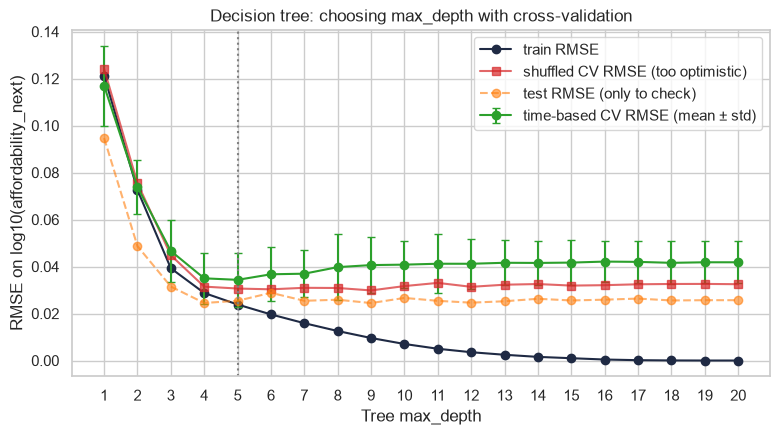

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
time_cv_mean,0.1170,0.0738,0.0466,0.0350,0.0343,0.0367,0.0370,0.0398,0.0406,0.0408,0.0412,0.0412,0.0416,0.0415,0.0417,0.0421,0.0420,0.0416,0.0418,0.0418
time_cv_std,0.0171,0.0115,0.0130,0.0109,0.0114,0.0115,0.0100,0.0140,0.0118,0.0100,0.0126,0.0106,0.0096,0.0093,0.0094,0.0089,0.0091,0.0092,0.0090,0.0090
shuffled_cv_mean,0.1241,0.0755,0.0448,0.0315,0.0306,0.0303,0.0310,0.0309,0.0298,0.0317,0.0330,0.0314,0.0323,0.0326,0.0319,0.0321,0.0325,0.0326,0.0326,0.0325
train,0.1213,0.0726,0.0393,0.0287,0.0238,0.0196,0.0159,0.0126,0.0096,0.0070,0.0050,0.0035,0.0024,0.0015,0.0010,0.0004,0.0001,0.0000,0.0000,0.0000
test,0.0947,0.0487,0.0315,0.0245,0.0254,0.0288,0.0254,0.0259,0.0245,0.0266,0.0254,0.0246,0.0252,0.0263,0.0256,0.0259,0.0264,0.0256,0.0257,0.0257


In [13]:
shuffled_kf = KFold(n_splits=5, shuffle=True, random_state=42)

depth_rows = []
for depth in range(1, 21):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    time_scores = -cross_val_score(tree, X_train, y_train, cv=time_folds,
                                   scoring="neg_root_mean_squared_error")
    shuffled_scores = -cross_val_score(tree, X_train, y_train, cv=shuffled_kf,
                                       scoring="neg_root_mean_squared_error")
    depth_rows.append({"max_depth": depth,
                       "time_cv_mean": time_scores.mean(), "time_cv_std": time_scores.std(),
                       "shuffled_cv_mean": shuffled_scores.mean()})
cv_tree = pd.DataFrame(depth_rows).merge(tree_sweep, on="max_depth")

best_depth = int(cv_tree.loc[cv_tree["time_cv_mean"].idxmin(), "max_depth"])
print(f"max_depth chosen by time-based CV: {best_depth}")

plt.figure(figsize=(9, 4.5))
plt.plot(cv_tree["max_depth"], cv_tree["train"], "o-", color="#1f2a44", label="train RMSE")
plt.errorbar(cv_tree["max_depth"], cv_tree["time_cv_mean"], yerr=cv_tree["time_cv_std"],
             fmt="o-", color="tab:green", capsize=3, label="time-based CV RMSE (mean ± std)")
plt.plot(cv_tree["max_depth"], cv_tree["shuffled_cv_mean"], "s-", color="tab:red", alpha=0.7,
         label="shuffled CV RMSE (too optimistic)")
plt.plot(cv_tree["max_depth"], cv_tree["test"], "o--", color="tab:orange", alpha=0.6, label="test RMSE (only to check)")
plt.axvline(best_depth, color="grey", linestyle=":")
plt.xticks(range(1, 21))
plt.xlabel("Tree max_depth")
plt.ylabel("RMSE on log10(affordability_next)")
plt.title("Decision tree: choosing max_depth with cross-validation")
plt.legend()
plt.show()

cv_tree.round(4).set_index("max_depth").T

### Final check on the test set (once)

With the depth chosen by cross-validation, we train on the **full** training set (1977–2014) and evaluate **once** on the test set (2015–2024).

In [14]:
final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(X_train, y_train)
test_rmse = root_mean_squared_error(y_test, final_tree.predict(X_test))
cv_at_best = cv_tree.loc[cv_tree["max_depth"] == best_depth].iloc[0]

print(f"max_depth = {best_depth}")
print(f"time-based CV RMSE: {cv_at_best['time_cv_mean']:.4f} ± {cv_at_best['time_cv_std']:.4f}")
print(f"shuffled CV RMSE:   {cv_at_best['shuffled_cv_mean']:.4f}")
print(f"test RMSE:          {test_rmse:.4f}  (≈ {(10 ** test_rmse - 1):.1%} typical error on affordability)")

max_depth = 5
time-based CV RMSE: 0.0343 ± 0.0114
shuffled CV RMSE:   0.0306
test RMSE:          0.0254  (≈ 6.0% typical error on affordability)


### What we see

**Synthetic example**
- 5-fold CV picks **degree 2**, the true shape of the curve, without ever looking at the test set. Its CV error (≈ 6.1) is close to the test error (≈ 6.5).
- For high degrees the CV error is not only higher but also much more **spread out** across folds (large error bars): an overfitted model is unstable and depends heavily on which points it happened to see.

**Housing data**
- Time-based CV picks **max_depth = 5** (CV RMSE ≈ 0.034 ± 0.011), close to the best depth we saw on the test set in 1.2, but this time chosen honestly.
- **Shuffled CV is too optimistic:** from depth 4 onwards it reports lower errors than time-based CV (e.g. 0.030 vs 0.042 at depth 9) and its minimum sits at a deeper tree. The model is rewarded for "seeing" neighbouring years, which it cannot do when forecasting.
- **Final test RMSE ≈ 0.025** (≈ 6% typical error). It is even lower than the CV estimate. This is not a mistake: the CV folds include volatile periods (1980s–90s, the 2008 crisis), while 2015–2024 was calmer. The CV score is the more cautious estimate to report.

**Takeaway:** use cross-validation on the training set to compare models and choose hyperparameters; touch the test set **once**, at the end. On time-ordered data, the folds must respect time too.

### Why not a single validation split?

With one split, the score depends on *which* rows happened to land in the validation part (lucky or unlucky). Averaging over 5 splits is more **stable**, and the **standard deviation** of the 5 scores tells us how much the score could change by chance.

Below: the same degree-2 model scored with 50 different single 80/20 splits of the synthetic training points, compared with 50 runs of 5-fold CV (each with a different shuffle).

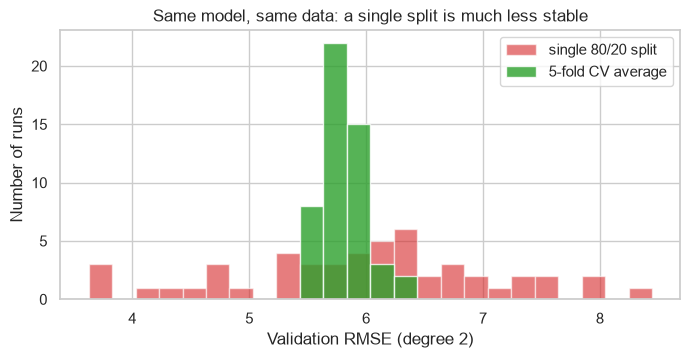

single split: 3.6 to 8.4 (std 1.09)
5-fold CV:    5.5 to 6.4 (std 0.19)


In [15]:
from sklearn.model_selection import ShuffleSplit

model = make_pipeline(PolynomialFeatures(2), StandardScaler(), LinearRegression())
X_wwr = wwr_train.reshape(-1, 1)

single_split, five_fold = [], []
for seed in range(50):
    single = ShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    single_split.append(-cross_val_score(model, X_wwr, dem_train, cv=single,
                                         scoring="neg_root_mean_squared_error")[0])
    folds = KFold(n_splits=5, shuffle=True, random_state=seed)
    five_fold.append(-cross_val_score(model, X_wwr, dem_train, cv=folds,
                                      scoring="neg_root_mean_squared_error").mean())

bins = np.linspace(min(single_split), max(single_split), 25)
plt.figure(figsize=(8, 3.5))
plt.hist(single_split, bins=bins, alpha=0.6, color="tab:red", label="single 80/20 split")
plt.hist(five_fold, bins=bins, alpha=0.8, color="tab:green", label="5-fold CV average")
plt.xlabel("Validation RMSE (degree 2)")
plt.ylabel("Number of runs")
plt.title("Same model, same data: a single split is much less stable")
plt.legend()
plt.show()

print(f"single split: {np.min(single_split):.1f} to {np.max(single_split):.1f} (std {np.std(single_split):.2f})")
print(f"5-fold CV:    {np.min(five_fold):.1f} to {np.max(five_fold):.1f} (std {np.std(five_fold):.2f})")

## 1.4 Baselines

Before celebrating a score, ask: *what score would a "dumb" model get?* A **baseline** is the simplest possible prediction:
- **Regression:** always predict the **mean** of the training targets.
- **Classification:** always predict the **most frequent class**.

scikit-learn has these as `DummyRegressor` and `DummyClassifier`. If your model cannot clearly beat the baseline, it has not learned anything useful.

For our forecasting task there is a second, much stronger baseline: **"next year = this year"** (persistence). On Day 1 we saw that this year's affordability correlates ≈ 0.99 with next year's (README §8.3), so this simple rule will already score very well. It is the real bar our models must clear.

`cross_validate` runs cross-validation for us: it gives back the score of each of the 5 folds. We use the same time-based folds as in 1.3.

In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import cross_validate

class PersistenceRegressor(RegressorMixin, BaseEstimator):
    """Baseline: next year's affordability = this year's affordability."""
    def fit(self, X, y):
        return self  # nothing to learn

    def predict(self, X):
        return np.log10(X["affordability"].to_numpy())

models = {
    "Baseline: mean": DummyRegressor(strategy="mean"),
    "Baseline: next year = this year": PersistenceRegressor(),
    f"Decision tree (max_depth={best_depth})": DecisionTreeRegressor(max_depth=best_depth, random_state=42),
}

fold_scores = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=time_folds,
                         scoring="neg_root_mean_squared_error")
    fold_scores[name] = -res["test_score"]

fold_table = pd.DataFrame(fold_scores, index=[f"Fold {i + 1}" for i in range(5)]).T
fold_table["mean"] = fold_table.mean(axis=1)
fold_table["std"] = fold_table.iloc[:, :5].std(axis=1, ddof=0)
fold_table.round(4)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,mean,std
Baseline: mean,0.2171,0.1789,0.1291,0.1186,0.0919,0.1471,0.0449
Baseline: next year = this year,0.0341,0.0254,0.0259,0.0278,0.0194,0.0265,0.0047
Decision tree (max_depth=5),0.0566,0.0323,0.0295,0.0272,0.0260,0.0343,0.0114


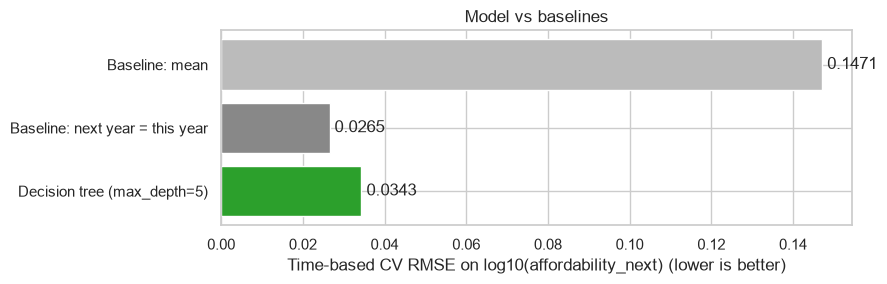

,CV RMSE,test RMSE,typical error
model,,,
Baseline: mean,0.1471,0.0652,≈ 16.2%
Baseline: next year = this year,0.0265,0.0222,≈ 5.3%
Decision tree (max_depth=5),0.0343,0.0254,≈ 6.0%


In [17]:
# final check on the test set, once, for the baselines and the tree
test_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rmse = root_mean_squared_error(y_test, model.predict(X_test))
    test_rows.append({"model": name, "CV RMSE": fold_table.loc[name, "mean"], "test RMSE": rmse,
                      "typical error": f"≈ {10 ** rmse - 1:.1%}"})
results = pd.DataFrame(test_rows).set_index("model")

fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(results.index, results["CV RMSE"], color=["#bbbbbb", "#888888", "tab:green"])
for i, v in enumerate(results["CV RMSE"]):
    ax.text(v, i, f" {v:.4f}", va="center")
ax.invert_yaxis()
ax.set_xlabel("Time-based CV RMSE on log10(affordability_next) (lower is better)")
ax.set_title("Model vs baselines")
plt.tight_layout()
plt.show()

results.round(4)

### What we see

**Single split vs cross-validation:** the same degree-2 model gets anything from ≈ 3.6 to 8.4 with a single 80/20 split, depending only on which points land in validation. The 5-fold average stays between ≈ 5.5 and 6.4, about **5× more stable** (std 0.19 vs 1.09).

**Baselines on the housing data**
- **Mean baseline:** CV RMSE ≈ 0.147 (≈ 16% typical error on the test set). The decision tree beats it easily, so it has learned *something*.
- **"Next year = this year":** CV RMSE ≈ **0.027**, better than the tree's ≈ 0.034, in every fold except fold 4 where the two are nearly tied. On the test set the same: 0.022 vs 0.025 (≈ 5.3% vs 6.0%).
- So the decision tree does **not** beat the honest baseline. Beating the mean baseline alone would have made it look good; the persistence baseline shows it adds no value yet.

**Why the tree struggles:** a tree can only predict values it has seen in its leaves (averages of groups of training rows). Affordability drifts to new levels over time, so a tree predicting the *level* loses precision that simply copying this year's value keeps.

**For the next sections:** every model we try must be compared against **"next year = this year"**, not just the mean. A promising idea is to predict the **change** from this year to next year instead of the level, so that the model only has to learn the part persistence cannot.

### R² of the baselines

The mean baseline has an **R² of 0** by definition (see section 4.2): R² measures how much better a model is than always predicting the mean. Every real model must do clearly better than this.

One subtlety on our data: the baseline predicts the mean of the **training** years, but is scored on **later** years whose mean is different (affordability drifts over time). So its R² comes out **below 0**, which means "worse than knowing the mean of the period being predicted": about −0.1 in cross-validation, and almost −1 on the test set, because 2015–2024 is a calm period with little spread, so even a modest miss of the level is large compared with it.

In [18]:
r2_rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=time_folds, scoring="r2")
    model.fit(X_train, y_train)
    r2_rows.append({"model": name, "CV R²": res["test_score"].mean(),
                    "test R²": model.score(X_test, y_test)})
pd.DataFrame(r2_rows).set_index("model").round(3)

,CV R²,test R²
model,,
Baseline: mean,-0.100,-0.974
Baseline: next year = this year,0.958,0.770
Decision tree (max_depth=5),0.937,0.699


## 1.5 Data leakage

**Data leakage** happens when information that would **not be available at prediction time** sneaks into the training data. The model then looks brilliant in the notebook and fails in the real world.

On Day 1 we removed two leaking features (`affordability_vs_own_avg`, `affordability_position`) because they use each country's average, minimum and maximum over **all** years, including the future. Here we show a more blatant case, the kind that is easy to create by accident during feature engineering: **next year's growth in affordability**.

It is computed from the target: `growth_next = affordability_next / affordability`. So

`log10(affordability_next) = log10(affordability) + log10(growth_next)`

If we give the model this growth, it does not need to learn anything. Let's see what happens with a linear regression:

In [19]:
# honest inputs: our features plus this year's affordability on the same log scale as the target
X_honest = X.assign(log_affordability=np.log10(df["affordability"]))
# leaky inputs: the same, plus next year's growth (computed from the target!)
X_leaky = X_honest.assign(log_growth_next=np.log10(df["affordability_next"] / df["affordability"]))

leak_rows = []
for label, X_variant in {"honest features": X_honest, "+ next year's growth (leak)": X_leaky}.items():
    Xv_train, Xv_test = X_variant[is_train], X_variant[~is_train]
    res = cross_validate(LinearRegression(), Xv_train, y_train, cv=time_folds,
                         scoring=["neg_root_mean_squared_error", "r2"])
    lr = LinearRegression().fit(Xv_train, y_train)
    leak_rows.append({"inputs": label,
                      "CV RMSE": -res["test_neg_root_mean_squared_error"].mean(),
                      "CV R²": res["test_r2"].mean(),
                      "test RMSE": root_mean_squared_error(y_test, lr.predict(Xv_test)),
                      "test R²": lr.score(Xv_test, y_test)})
pd.DataFrame(leak_rows).set_index("inputs").round(4)

,CV RMSE,CV R²,test RMSE,test R²
inputs,,,,
honest features,0.0222,0.9718,0.0192,0.8279
+ next year's growth (leak),0.0000,1.0000,0.0000,1.0000


A **perfect score is a red flag**, not a reason to celebrate. In real life, when we forecast affordability for 2026 at the end of 2025, we do not know the growth from 2025 to 2026, because that is computed **from the answer** we are trying to predict!

Note that leakage does not always show up as a better score. Adding back the two Day 1 features barely changes the decision tree's score, but they are still invalid: a model using them would rely on information (a country's future minimum, maximum and average) that it can never have when forecasting. **Leakage is about what is available at prediction time, not about the score.**

⚠️ **Watch out – the subtle kind of leakage:** leakage also happens when we fit preprocessing steps (imputers, scalers, encoders) on the **whole** dataset before splitting: the training data then "knows" something about the test data (e.g. its mean). The fix is to fit every preprocessing step **on the training data only**. Doing this by hand is error-prone… which is exactly why scikit-learn has **pipelines**.

Below, a K-nearest-neighbours model (which needs scaled inputs) is cross-validated twice:
- **Wrong:** `StandardScaler` fitted on **all** rows (including the test years) before cross-validation.
- **Right:** scaler and model in a **pipeline**, so in each fold the scaler is fitted only on that fold's training rows.

In [20]:
from sklearn.neighbors import KNeighborsRegressor

# WRONG: scale using statistics of the whole dataset, then cross-validate
X_scaled_all = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)
wrong = -cross_val_score(KNeighborsRegressor(n_neighbors=5), X_scaled_all[is_train], y_train,
                         cv=time_folds, scoring="neg_root_mean_squared_error")

# RIGHT: the pipeline refits the scaler inside every fold, on training rows only
knn_pipeline = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
right = -cross_val_score(knn_pipeline, X_train, y_train,
                         cv=time_folds, scoring="neg_root_mean_squared_error")

pd.DataFrame({"scaler fitted on all data (leak)": wrong, "pipeline (correct)": right},
             index=[f"Fold {i + 1}" for i in range(5)]).T.assign(mean=lambda t: t.mean(axis=1)).round(4)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,mean
scaler fitted on all data (leak),0.0777,0.0529,0.0692,0.0726,0.0541,0.0653
pipeline (correct),0.0943,0.0782,0.0828,0.0835,0.0677,0.0813


### What we see

- **R²:** the mean baseline scores ≈ −0.1 (CV) and ≈ −0.97 (test); "next year = this year" already reaches ≈ 0.96 (CV) and ≈ 0.77 (test). A high R² on its own means little for this task, because persistence gets most of it for free.
- **Target leakage:** adding next year's growth gives a **perfect** score: RMSE = 0 and R² = 1, in every fold and on the test set. The model simply adds the two logs together. This is the clearest possible red flag.
- **Preprocessing leakage:** fitting the scaler on all data makes KNN look ≈ **20% better** than it really is (CV RMSE 0.065 vs 0.081), and better in every fold. The scaler "knew" the range of the test years (e.g. that `year` goes up to 2024). The pipeline gives the honest number.
- **Side note:** the *honest* linear regression, which only gets this year's affordability on the log scale, reaches CV RMSE ≈ 0.022 and test RMSE ≈ 0.019. That is the first model in this notebook to **beat "next year = this year"** (0.027 and 0.022). We come back to it in the next sections.

**Takeaway:** for every input, ask *"would I know this value at the moment I make the prediction?"*, and put all preprocessing inside a pipeline so it is refitted on training data only.

# 2. scikit-learn pipelines and encoders

## 2.1 The scikit-learn API: fit, transform, predict

We have already used several scikit-learn objects in this notebook (`StandardScaler`, `LinearRegression`, `DecisionTreeRegressor`, `DummyRegressor`). Every object in scikit-learn follows the same small set of methods, which makes them easy to combine:

| Type of object | Examples | Methods | What it does |
|---|---|---|---|
| **Transformer** | `SimpleImputer`, `StandardScaler`, `OneHotEncoder` | `fit()` + `transform()` (or `fit_transform()`) | **Learns** something from the data (a median, a mean, a list of categories) and then **changes** the data |
| **Estimator / model** | `LinearRegression`, `RandomForestClassifier` | `fit()` + `predict()` | **Learns** the relation between `X` and `y` and **predicts** `y` for new `X` |

The golden rule: **`fit` only on training data**, then `transform` / `predict` on anything.

Even our own `PersistenceRegressor` from 1.4 follows this API (a `fit` that learns nothing and a `predict`), which is why `cross_validate` could use it like any other model.

## 2.2 The problem pipelines solve

Let's train a small model on three numeric columns with very different scales:
- `year`: values around **2000**
- `affordability`: values from about **40 to 600**
- `real_hpi_change_pct`: yearly change in real house prices, roughly **−25 to +30**

A K-nearest-neighbours model compares rows by distance, so without rescaling, the column with the biggest numbers dominates. We use a **scaler**: `StandardScaler` rescales each column to mean 0 and standard deviation 1.

Our model-ready file has **no missing values** (Day 1 removed the rows without lags or target). But in real use, the newest year's statistics often arrive late or incomplete, so a model should be able to handle gaps. To practise, we **simulate** this by blanking out 5% of the values in each column at random, and add an **imputer** (`SimpleImputer`, filling gaps with the column median).

**Version 1: by hand.**

In [21]:
from sklearn.impute import SimpleImputer

cols = ["year", "affordability", "real_hpi_change_pct"]

# simulated gaps: blank out 5% of each column at random (a copy, the real data is untouched)
gap_rng = np.random.default_rng(0)
X_small = df[cols].copy()
for col in cols:
    X_small.loc[gap_rng.random(len(X_small)) < 0.05, col] = np.nan

X_small_train, X_small_test = X_small[is_train], X_small[~is_train]
print("Missing values in train:", X_small_train.isna().sum().to_dict())
print("Missing values in test: ", X_small_test.isna().sum().to_dict())
X_small_train.describe().round(1)

Missing values in train: {'year': 43, 'affordability': 55, 'real_hpi_change_pct': 47}
Missing values in test:  {'year': 13, 'affordability': 22, 'real_hpi_change_pct': 10}


,year,affordability,real_hpi_change_pct
count,907.0,895.0,903.0
mean,1995.9,101.5,1.6
std,10.9,62.1,7.1
min,1977.0,37.3,-25.3
25%,1986.0,71.4,-2.7
50%,1996.0,89.3,1.1
75%,2005.0,112.4,5.7
max,2014.0,622.8,30.6


In [22]:
# Step 1: imputer, learns the median of each column on the TRAINING data only
imputer = SimpleImputer(strategy="median")
X_tr = imputer.fit_transform(X_small_train)
X_te = imputer.transform(X_small_test)          # transform only, never fit on test

# Step 2: scaler, learns mean and std of each column on the TRAINING data only
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr)
X_te = scaler.transform(X_te)

# Step 3: model
knn = KNeighborsRegressor(n_neighbors=10)
knn.fit(X_tr, y_train)
y_pred = knn.predict(X_te)

print("Medians learned by the imputer:", {c: round(float(v), 1) for c, v in zip(cols, imputer.statistics_)})
print("Means learned by the scaler:   ", {c: round(float(v), 1) for c, v in zip(cols, scaler.mean_)})
print(f"Test RMSE: {root_mean_squared_error(y_test, y_pred):.4f}")

Medians learned by the imputer: {'year': 1996.0, 'affordability': 89.3, 'real_hpi_change_pct': 1.1}
Means learned by the scaler:    {'year': 1995.9, 'affordability': 100.8, 'real_hpi_change_pct': 1.6}
Test RMSE: 0.0395


This works, but look at how much can go wrong:
- **Six steps** that must run in exactly the right order, with the right `fit_transform` / `transform` on each side.
- One slip, such as `imputer.fit_transform(X_small_test)` or scaling before splitting, is **silent leakage** (1.5): no error, just a score that is too good.
- To make a prediction for a new year, we must remember to repeat **every** step with the **same** fitted imputer and scaler.
- It does not work with `cross_val_score`: in each fold the imputer and scaler would have to be refitted on that fold's training rows, which means writing the loop ourselves.

We evaluated on the test set here only to show the mechanics. A pipeline solves all four problems.

It works, but every step must be repeated in the right order, with `fit_transform` in one place and `transform` in the other. Forget one, or use `fit_transform` on the test data by mistake, and you get wrong results or leakage. Now imagine doing this inside 5-fold cross-validation…

**Version 2: with a `Pipeline`.** A pipeline chains the steps into **one object** that behaves like a model: one `fit`, one `predict`.

In [23]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=10)),
])

pipe.fit(X_small_train, y_train)          # fits imputer, scaler and model, all on training data
y_pred_pipe = pipe.predict(X_small_test)  # only transforms the test data, then predicts

print(f"Test RMSE (pipeline): {root_mean_squared_error(y_test, y_pred_pipe):.4f}")
print("Same predictions as the by-hand version:", np.allclose(y_pred, y_pred_pipe))
pipe

Test RMSE (pipeline): 0.0395
Same predictions as the by-hand version: True


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['year','affordability','real_hpi_change_pct']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, 

Same result, but now the whole recipe is **one object**. It can go straight into cross-validation, and in every fold the imputer and scaler are refitted on that fold's training rows only, with no extra code:

In [24]:
pipe_scores = -cross_val_score(pipe, X_small_train, y_train, cv=time_folds,
                               scoring="neg_root_mean_squared_error")
print("RMSE per fold:", pipe_scores.round(4))
print(f"CV RMSE: {pipe_scores.mean():.4f} ± {pipe_scores.std():.4f}")

RMSE per fold: [0.1324 0.1066 0.0795 0.0827 0.045 ]
CV RMSE: 0.0892 ± 0.0292


(We just peeked at the test set to show that both versions are identical. From now on, the test set stays locked until section 4.7.)

## 2.3 Encoding categorical variables

Models only understand **numbers**. Columns that contain text must be **encoded**. First we need to know what *kind* of category we have:

| Kind | Meaning | Examples in our data |
|---|---|---|
| **Nominal** | Categories with **no natural order** | `region` (Nordic is not "more" than Oceania), `country` / `iso` |
| **Ordinal** | Categories with a **meaningful order** | `decade`: 1970s < 1980s < … < 2020s |

In the model-ready file, Day 1 already one-hot encoded `region` into ten 0/1 columns (`region_Africa`, `region_Asia`, …). To see how the encoders work, we rebuild the original text column from them, and write `decade` as text labels.

Let's look at the main encoders on 5 example rows:

In [25]:
region_cols = [c for c in df.columns if c.startswith("region_")]

cat_df = pd.DataFrame({
    "country": df["iso"],
    "region": df[region_cols].idxmax(axis=1).str.removeprefix("region_"),
    "decade": df["decade"].astype(str) + "s",
})

# 5 rows with different regions and decades
picks = [("AUS", 1979), ("KOR", 1988), ("FIN", 1995), ("USA", 2007), ("ESP", 2021)]
rows = [df.index[(df["iso"] == iso) & (df["year"] == year)][0] for iso, year in picks]
examples = cat_df.loc[rows].reset_index(drop=True)
examples

,country,region,decade
0,AUS,Oceania,1970s
1,KOR,Asia,1980s
2,FIN,Nordic,1990s
3,USA,North America,2000s
4,ESP,Southern Europe,2020s


In [26]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Nominal -> OneHotEncoder: one 0/1 column per category, no order implied
onehot = OneHotEncoder(sparse_output=False)
region_onehot = pd.DataFrame(onehot.fit_transform(examples[["region"]]),
                             columns=onehot.get_feature_names_out(), dtype=int)

# Ordinal -> OrdinalEncoder with the order spelled out: 1970s=0, 1980s=1, ...
decade_order = ["1970s", "1980s", "1990s", "2000s", "2010s", "2020s"]
ordinal = OrdinalEncoder(categories=[decade_order])
decade_ordinal = pd.DataFrame(ordinal.fit_transform(examples[["decade"]]),
                              columns=["decade_ordinal"], dtype=int)

pd.concat([examples, region_onehot, decade_ordinal], axis=1)

,country,region,decade,region_Asia,region_Nordic,region_North America,region_Oceania,region_Southern Europe,decade_ordinal
0,AUS,Oceania,1970s,0,0,0,1,0,0
1,KOR,Asia,1980s,1,0,0,0,0,1
2,FIN,Nordic,1990s,0,1,0,0,0,2
3,USA,North America,2000s,0,0,1,0,0,3
4,ESP,Southern Europe,2020s,0,0,0,0,1,5


### One-hot encoding: `OneHotEncoder`

Creates **one 0/1 column per category**. A row from Finland gets a 1 in the `region_Nordic` column and 0 everywhere else. No order is invented: each category is simply "present" or "absent". This is the **default choice for nominal categories**.

⚠️ **Watch out:** one-hot encoding creates **many columns** when there are many categories: `region` has 10 categories → 10 columns, `country` has 26 → 26 columns. That is fine, but it would not be for 10,000 categories (e.g. if we had city- or neighbourhood-level data). Also, a category that appears in new data but never in training would **crash** the encoder; `handle_unknown="ignore"` turns it into all zeros instead.

Below, the encoder learns the 26 countries from the training data, and then meets **Mexico**, which is not in our dataset:

In [27]:
country_train = cat_df.loc[is_train, ["country"]]
new_rows = pd.DataFrame({"country": ["ESP", "MEX"]})   # MEX never seen in training

strict = OneHotEncoder(sparse_output=False).fit(country_train)
try:
    strict.transform(new_rows)
except ValueError as e:
    print("Default encoder:", str(e).split("\n")[0])

tolerant = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(country_train)
encoded = pd.DataFrame(tolerant.transform(new_rows), columns=tolerant.get_feature_names_out(),
                       index=new_rows["country"], dtype=int)
print(f"\nWith handle_unknown='ignore': {encoded.shape[1]} columns; MEX row sums to {encoded.loc['MEX'].sum()}")
encoded[["country_DEU", "country_ESP", "country_FRA", "country_USA"]]

Default encoder: Found unknown categories ['MEX'] in column 0 during transform

With handle_unknown='ignore': 26 columns; MEX row sums to 0


,country_DEU,country_ESP,country_FRA,country_USA
country,,,,
ESP,0,1,0,0
MEX,0,0,0,0


### Ordinal encoding: `OrdinalEncoder`

Replaces each category with an **integer**. It is the right choice when the order is real, and we must **tell the encoder the order**: otherwise it uses **alphabetical** order!

`decade` happens to sort correctly in alphabetical order ("1970s" < "1980s" < …), so it cannot show the problem. We use an **illustrative affordability band** built from this year's affordability (cut-offs chosen only for this example):

| Band | Affordability |
|---|---|
| Affordable | below 80 |
| Moderate | 80–100 |
| Unaffordable | 100–130 |
| Severely unaffordable | 130 and above |

Alphabetically, "Severely unaffordable" would come **before** "Unaffordable", which is wrong.

We also add a row whose value is **`Unknown`** (as if Italy's latest statistics had not been published yet, like the simulated gaps in 2.2). `Unknown` is not in the list, so we place it at **-1**: outside the 0–3 scale, so the model can tell it apart from a real band. Unlike a real price listing, we have no evidence that missing values mean "cheap" here, so -1 is only a marker, not a claim about affordability.

In [28]:
bands = ["Affordable", "Moderate", "Unaffordable", "Severely unaffordable"]
affordability_band = pd.cut(df["affordability"], bins=[0, 80, 100, 130, np.inf], labels=bands, right=False)

band_examples = examples[["country", "decade"]].copy()
band_examples["affordability"] = df.loc[rows, "affordability"].round(1).to_numpy()
band_examples["band"] = affordability_band.loc[rows].astype(str).to_numpy()
band_examples.loc[len(band_examples)] = ["ITA", "2020s", np.nan, "Unknown"]   # value not published yet

# WRONG: no order given -> alphabetical
alphabetical = OrdinalEncoder().fit(band_examples[["band"]])
band_examples["band_alphabetical"] = alphabetical.transform(band_examples[["band"]]).astype(int)

# RIGHT: order spelled out, Unknown -> -1
ordered = OrdinalEncoder(categories=[bands], handle_unknown="use_encoded_value", unknown_value=-1)
ordered.fit(band_examples.loc[band_examples["band"] != "Unknown", ["band"]])
band_examples["band_ordinal"] = ordered.transform(band_examples[["band"]]).astype(int)

print("Alphabetical order:", list(alphabetical.categories_[0]))
print("Our order:         ", list(ordered.categories_[0]))
band_examples

Alphabetical order: ['Affordable', 'Moderate', 'Severely unaffordable', 'Unaffordable', 'Unknown']
Our order:          ['Affordable', 'Moderate', 'Unaffordable', 'Severely unaffordable']


,country,decade,affordability,band,band_alphabetical,band_ordinal
0,AUS,1970s,38.9,Affordable,0,0
1,KOR,1980s,371.7,Severely unaffordable,2,3
2,FIN,1990s,92.4,Moderate,1,1
3,USA,2000s,101.1,Unaffordable,3,2
4,ESP,2020s,102.0,Unaffordable,3,2
5,ITA,2020s,NaN,Unknown,4,-1


**What we see**
- **One-hot:** the default encoder **crashes** on Mexico; with `handle_unknown="ignore"` Mexico simply gets 0 in all 26 country columns, while Spain gets a 1 in `country_ESP`.
- **Ordinal, alphabetical (wrong):** Korea 1988 ("Severely unaffordable") gets **2**, *lower* than the USA 2007 ("Unaffordable", **3**), and `Unknown` gets **4**, as if a missing value were the least affordable of all. A model would learn from this invented order.
- **Ordinal, with our order (right):** Affordable 0 < Moderate 1 < Unaffordable 2 < Severely unaffordable 3, and `Unknown` sits apart at **-1**.

### "Label encoding": `LabelEncoder`

When people say "label encoding" they usually mean: give each category an integer, in alphabetical order. scikit-learn's `LabelEncoder` does exactly that, but note its name: it is designed for **labels**, i.e. the **target `y`** of a classification problem (we use it in Part B), **not for features**.

Let's see what it does to `region`:

In [29]:
from sklearn.preprocessing import LabelEncoder

label_enc = LabelEncoder()
region_codes = label_enc.fit_transform(cat_df["region"])

pd.DataFrame({"region": label_enc.classes_,
              "code": label_enc.transform(label_enc.classes_)}).set_index("region").T

region,Africa,Asia,Central/Eastern Europe,Latin America,Middle East,Nordic,North America,Oceania,Southern Europe,Western Europe
code,0,1,2,3,4,5,6,7,8,9


The codes are alphabetical. A linear model would now believe that **Western Europe (9) is "nine times more" than Asia (1)**, and that the Middle East (4) lies "between" Latin America (3) and the Nordic countries (5). These relations are **invented**: the encoding creates a fake order. For a nominal feature, this can badly mislead some models (we measure the damage in section 4.3).

### Target encoding: `TargetEncoder`

A cleverer option for nominal columns with **many** categories: replace each category with the **average target** of that category (here: each country with its average `log10(affordability_next)`). One column instead of 26, and the numbers are meaningful.

⚠️ **Watch out:** it uses the target, so it can leak. scikit-learn's `TargetEncoder` protects against this with an internal cross-validation when you call `fit_transform`: each row is encoded with averages computed **without** the rows in its own fold, so a row never sees its own target.

We fit it on the **training** years only:

In [30]:
from sklearn.preprocessing import TargetEncoder

country_train = cat_df.loc[is_train, ["country"]]

# internal 5-fold cross-fitting (shuffled), used only by fit_transform
target_enc = TargetEncoder(target_type="continuous", cv=KFold(n_splits=5, shuffle=True, random_state=42))
country_encoded = target_enc.fit_transform(country_train, y_train)   # cross-fitted: safe for training rows

te_table = pd.DataFrame({
    "plain average (leaks)": y_train.groupby(country_train["country"]).mean(),
    "encoding for new data": pd.Series(target_enc.encodings_[0], index=target_enc.categories_[0]),
    "fit_transform: min": pd.Series(country_encoded[:, 0], index=country_train.index).groupby(country_train["country"]).min(),
    "fit_transform: max": pd.Series(country_encoded[:, 0], index=country_train.index).groupby(country_train["country"]).max(),
})
te_table.sort_values("plain average (leaks)").round(3)

,plain average (leaks),encoding for new data,fit_transform: min,fit_transform: max
LUX,1.732,1.734,1.723,1.748
AUS,1.755,1.756,1.746,1.769
NZL,1.760,1.762,1.746,1.793
CAN,1.784,1.785,1.778,1.795
NLD,1.852,1.853,1.844,1.860
GBR,1.861,1.862,1.849,1.876
BEL,1.876,1.877,1.860,1.886
IRL,1.891,1.892,1.888,1.900
SWE,1.893,1.893,1.881,1.908
ISR,1.905,1.905,1.898,1.910


**What we see**
- **One column instead of 26.** Each country gets one number: from ≈ 1.73 (Luxembourg) to ≈ 2.36 (South Korea).
- **But read these numbers carefully.** Luxembourg, Australia, New Zealand and Canada get the *lowest* values, although on Day 1 they were the *least* affordable since 2000. The reason is in the README limitations: our columns are **indexes, not money**. Each country's index is relative to its own base year, so the level mostly tells us how far a country has moved from its base, not how affordable it is compared with other countries. Target encoding faithfully learns this artefact. Always check that the encoded numbers make sense.
- The **plain average** uses every training row's own target, so a model trained on it would partly be fed the answer.
- **`fit_transform`** gives each row a value from the *other* folds, so rows of the same country get slightly different values (min ≠ max). The column "encoding for new data" is what `transform` will use later on validation and test rows. The values are also **shrunk** a little towards the overall average (smoothing), which protects small categories: Korea, the most extreme, is shrunk the most (2.361 → 2.339).
- The internal cross-validation shuffles rows, so on our data a row can still be encoded using neighbouring years of the same country. With only 26 countries, one-hot encoding is simpler and safer; target encoding pays off with hundreds or thousands of categories.

### Which encoder should I use?

| Kind of column | Linear models, KNN | Tree-based models (tree, random forest, gradient boosting) |
|---|---|---|
| **Nominal, few categories** | **One-hot** | One-hot (or ordinal: trees are more tolerant of fake orders) |
| **Nominal, many categories** | One-hot, or **target encoding** | One-hot, ordinal or target encoding |
| **Ordinal** | **Ordinal** with the right order | **Ordinal** with the right order |
| **Target `y`** (classification) | `LabelEncoder` (or keep the strings: scikit-learn accepts text labels) | same |

**For our data:** `region` (10 categories) → **one-hot**; `decade` → **ordinal** with the order 1970s < … < 2020s. `country` (26) would also be one-hot, but we leave it out of the model: with one column per country, the model could simply memorise each country's index level (which, as we saw with target encoding, is an artefact of the index base year).

## 2.4 `ColumnTransformer`: different preprocessing for different columns

Real datasets mix numeric and categorical columns, and each kind needs its own preprocessing:

| Columns | Preprocessing |
|---|---|
| **Numeric** | Fill missing values (median) → scale |
| **Nominal categorical** | Fill missing values (most frequent) → one-hot encode |
| **Ordinal categorical** | Ordinal encode with the correct order |

A `ColumnTransformer` applies each mini-pipeline to its own list of columns and glues the results together side by side.

Our model-ready file already contains `region` as ten 0/1 columns and `decade` as a number. To use a `ColumnTransformer` the way it is meant to be used (on **raw** columns), we rebuild them as text, exactly like a fresh dataset would arrive. We also keep `log_affordability` from 1.5 as a numeric input.

In [31]:
from sklearn.compose import ColumnTransformer

# "raw" version of our inputs: numbers + region and decade as text
numeric_cols = [c for c in X.columns if not c.startswith("region_") and c != "decade"] + ["log_affordability"]
nominal_cols = ["region"]
ordinal_cols = ["decade"]

X_raw = pd.concat([X_honest[numeric_cols], cat_df[nominal_cols + ordinal_cols]], axis=1)
X_raw_train, X_raw_test = X_raw[is_train], X_raw[~is_train]

print(f"{len(numeric_cols)} numeric, {len(nominal_cols)} nominal, {len(ordinal_cols)} ordinal columns")
X_raw_train.head()

15 numeric, 1 nominal, 1 ordinal columns


,year,affordability,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,real_income_change_pct,affordability_lag1,affordability_lag2,affordability_3yr_avg,nominal_zero,hyperinflation_country,price_shock_up,price_shock_down,gfc_period,log_affordability,region,decade
0,1977,39.048834,21.43,54.88,-1.016166,-0.290698,39.335029,39.285714,39.223192,0,0,0,0,0,1.591608,Oceania,1970s
1,1978,38.061170,21.28,55.91,-0.699953,1.876822,39.048834,39.335029,38.815011,0,0,0,0,0,1.580482,Oceania,1970s
2,1979,38.880944,21.75,55.94,2.208647,0.053658,38.061170,39.048834,38.663649,0,0,0,0,0,1.589737,Oceania,1970s
3,1980,42.938456,24.14,56.22,10.988506,0.500536,38.880944,38.061170,39.960190,0,0,0,0,0,1.632846,Oceania,1980s
4,1981,44.351318,25.40,57.27,5.219553,1.867663,42.938456,38.880944,42.056906,0,0,0,0,0,1.646907,Oceania,1980s


In [32]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
nominal_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
ordinal_pipe = OrdinalEncoder(categories=[decade_order],
                              handle_unknown="use_encoded_value", unknown_value=-1)

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("nom", nominal_pipe, nominal_cols),
    ("ord", ordinal_pipe, ordinal_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [33]:
# fit on training data only, then look at what comes out
preprocess.set_output(transform="pandas")
X_prepared = preprocess.fit_transform(X_raw_train)

print(f"In:  {X_raw_train.shape[1]} columns  ->  Out: {X_prepared.shape[1]} columns")
X_prepared.head().round(2)

In:  17 columns  ->  Out: 26 columns


,num__year,num__affordability,num__real_house_price_index,num__real_personal_disposable_income,num__real_hpi_change_pct,num__real_income_change_pct,num__affordability_lag1,num__affordability_lag2,num__affordability_3yr_avg,num__nominal_zero,...,nom__region_Asia,nom__region_Central/Eastern Europe,nom__region_Latin America,nom__region_Middle East,nom__region_Nordic,nom__region_North America,nom__region_Oceania,nom__region_Southern Europe,nom__region_Western Europe,ord__decade
0,-1.73,-1.00,-1.49,-0.85,-0.36,-0.61,-0.97,-0.94,-0.98,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-1.64,-1.01,-1.50,-0.78,-0.32,0.08,-0.97,-0.94,-0.98,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-1.55,-1.00,-1.48,-0.78,0.09,-0.50,-0.99,-0.95,-0.98,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,-1.46,-0.93,-1.41,-0.76,1.32,-0.36,-0.98,-0.96,-0.96,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-1.37,-0.91,-1.36,-0.70,0.51,0.08,-0.91,-0.95,-0.93,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


Each output column name starts with the name of its mini-pipeline (`num__`, `nom__`, `ord__`), so we can always trace where it came from:
- the **15 numeric** columns are scaled (mean 0, std 1 on the training years),
- `region` became **10 one-hot** columns,
- `decade` became **one ordinal** column (1970s = 0, 1980s = 1, …).

The imputers do nothing on our complete training data, but they are now part of the recipe: a new row with missing values, or a region never seen in training, will not break it.

In [34]:
# a made-up incoming row for 2025: income not published yet, region missing
new_row = X_raw_train.iloc[[-1]].copy()
new_row[["real_personal_disposable_income", "real_income_change_pct"]] = np.nan
new_row["region"] = np.nan
new_row["year"] = 2025
new_row["decade"] = "2020s"

preprocess.transform(new_row).round(2)

,num__year,num__affordability,num__real_house_price_index,num__real_personal_disposable_income,num__real_hpi_change_pct,num__real_income_change_pct,num__affordability_lag1,num__affordability_lag2,num__affordability_3yr_avg,num__nominal_zero,...,nom__region_Asia,nom__region_Central/Eastern Europe,nom__region_Latin America,nom__region_Middle East,nom__region_Nordic,nom__region_North America,nom__region_Oceania,nom__region_Southern Europe,nom__region_Western Europe,ord__decade
1199,2.66,-0.38,-0.12,-0.05,0.27,-0.03,-0.39,-0.44,-0.4,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,5.0


The row went through without errors and still has 26 columns:
- the two missing income columns were filled with the **training median** and then scaled,
- the missing `region` was filled with the **most frequent** training region (Western Europe), so it gets a 1 in `nom__region_Western Europe`,
- `decade = "2020s"` became **5**, because we gave the encoder the full list of decades, even though no training row is from the 2020s.

Whether "most frequent region" is a sensible guess is a modelling choice; what matters is that the recipe is fixed, learned from training data only, and applied the same way to every new row.

Finally, the **full pipeline**: preprocessing + model, in **one** object.

In [35]:
full_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", LinearRegression()),
])
full_pipeline   # in Jupyter this shows an interactive diagram: click on the boxes to expand them

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('nom', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If 

We can fit it like any model and look inside it with `named_steps`. After preprocessing, our 17 original columns became 26, because of one-hot encoding:

In [36]:
full_pipeline.fit(X_raw_train, y_train)

feature_names = full_pipeline.named_steps["preprocess"].get_feature_names_out()
print(f"{X_raw_train.shape[1]} original columns -> {len(feature_names)} columns after preprocessing")
print("A few of them:", list(feature_names[:3]), "...", list(feature_names[15:18]))

17 original columns -> 26 columns after preprocessing
A few of them: ['num__year', 'num__affordability', 'num__real_house_price_index'] ... ['nom__region_Africa', 'nom__region_Asia', 'nom__region_Central/Eastern Europe']


## 2.5 Why pipelines matter

1. **No leakage in cross-validation.** When we pass a pipeline to `cross_validate`, the imputer, scaler and encoders are re-fitted **inside each fold**, on that fold's training part only (we measured the damage of not doing so in 1.5).
2. **Swap models with one line.** `full_pipeline.set_params(model=RandomForestRegressor())` keeps all the preprocessing and changes only the model.
3. **Tune everything together.** Each step's settings get a name `step__parameter`, e.g. `model__max_depth` or `preprocess__num__imputer__strategy`, which we can tune in a grid search (section 4.6).
4. **Save and reuse as one object.** The saved file contains the medians, the categories, the scaling *and* the model: you can give it a raw row of data and get a prediction (section 4.9).

## 2.6 A reusable helper

We will train many models, so we wrap the pipeline construction into a function. One detail: **linear models and KNN need scaling** (they compare or combine columns with different units), while **tree-based models don't** (they only ask questions like *"is affordability > 120?"*, which don't depend on the scale).

In [37]:
import time
import joblib

RANDOM_STATE = 42

# output folders at the repository root (works from the repo root or from notebook/)
ROOT = data_dir.parent
FIG_DIR = ROOT / "figures"
MODEL_DIR = ROOT / "models"
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)


def save_fig(name):
    path = FIG_DIR / f"day2_{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path.relative_to(ROOT)}")


def make_pipeline_for(model, numeric, nominal, ordinal=None, scale=True, nominal_encoder=None):
    # Build preprocessing + model as one Pipeline.
    #   model           : any scikit-learn model
    #   numeric         : list of numeric columns (imputed with the median, optionally scaled)
    #   nominal         : list of nominal categorical columns (one-hot encoded by default)
    #   ordinal         : dict {column: [categories in order]} for ordinal columns
    #   scale           : True for linear models / KNN, False for trees
    #   nominal_encoder : replace the default OneHotEncoder (e.g. OrdinalEncoder, TargetEncoder)
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    if nominal_encoder is None:
        nominal_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

    transformers = [
        ("num", Pipeline(numeric_steps), numeric),
        ("nom", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", nominal_encoder)]), nominal),
    ]
    if ordinal:
        transformers.append(("ord", OrdinalEncoder(categories=list(ordinal.values()),
                                                   handle_unknown="use_encoded_value",
                                                   unknown_value=-1), list(ordinal.keys())))

    return Pipeline([("preprocess", ColumnTransformer(transformers)), ("model", model)])


# Shortcut for our data: same columns every time (the raw columns from 2.4)
def affordability_pipeline(model, scale=True, nominal_encoder=None):
    return make_pipeline_for(model, numeric_cols, nominal_cols,
                             ordinal={"decade": decade_order},
                             scale=scale, nominal_encoder=nominal_encoder)

## 2.7 Saving and loading models

A trained pipeline can be saved to a file with `joblib` and loaded again later (in another notebook, a web app, a Grasshopper script…) without retraining. We do this in section 4.9 for our final model.

```python
joblib.dump(pipeline, "models/model.joblib")   # save
pipeline = joblib.load("models/model.joblib")  # load
```

# 3. The model zoo: types of supervised models

There are dozens of supervised models, but a handful of **families** cover most practical needs. All of them exist in a **regression** version (predict a number) and a **classification** version (predict a class).

### Linear models: `LinearRegression`, `Ridge`, `Lasso`, `LogisticRegression`
- **Idea:** the prediction is a **weighted sum** of the features: `log affordability next year ≈ w₁·log affordability + w₂·price growth + … + b`. Training finds the best weights.
- **Ridge / Lasso** add a penalty that keeps the weights small (*regularisation*), which reduces overfitting. Lasso can set weights to exactly 0 (automatic feature selection).
- **Logistic regression** is the classification version: a weighted sum turned into a probability.
- **Strengths:** fast, very **interpretable** (each weight has a meaning), works with little data.
- **Weaknesses:** can only draw **straight lines / flat planes**; misses non-linear effects and interactions unless you create them by hand.
- **Needs scaling:** yes (for regularisation and to compare weights).

### K-Nearest Neighbours: `KNeighborsRegressor`, `KNeighborsClassifier`
- **Idea:** *"tell me who your neighbours are"*. To predict a new country-year, find the K most **similar** country-years in the training data and average their values (or take the majority class).
- **Strengths:** simple, no training phase, captures any shape.
- **Weaknesses:** slow predictions on big datasets, sensitive to irrelevant features and to the **scale** of the features, struggles with many features.
- **Needs scaling:** yes, absolutely (distances!).

### Decision tree: `DecisionTreeRegressor`, `DecisionTreeClassifier`
- **Idea:** a flowchart of **yes/no questions**: *"Is affordability > 120? Did real prices grow more than 5%?"*. Each leaf gives a prediction.
- **Strengths:** **readable** (you can draw it), handles non-linear relations and interactions, no scaling needed.
- **Weaknesses:** a single deep tree **overfits** very easily; small changes in the data can change the whole tree.
- **Key hyperparameter:** `max_depth` (how many questions in a row).

### Random forest: `RandomForestRegressor`, `RandomForestClassifier`
- **Idea:** train **hundreds of trees**, each on a random sample of the rows and features, and **average** their predictions (*bagging*). The "wisdom of the crowd": individual trees overfit in different ways, and their errors cancel out.
- **Strengths:** accurate out of the box, robust, few settings to tune.
- **Weaknesses:** slower and heavier than one tree, less interpretable, **cannot predict beyond the range of the training data** (important for us: affordability keeps reaching new levels).

### Gradient boosting: `HistGradientBoostingRegressor`, `HistGradientBoostingClassifier`
- **Idea:** also many trees, but built **one after another**: each new small tree corrects the errors of the previous ones (*boosting*).
- **Strengths:** usually the **most accurate** model for **tabular data**. scikit-learn's "Hist" version is **fast** on large data and **handles missing values** by itself. (Popular alternatives: XGBoost, LightGBM, CatBoost.)
- **Weaknesses:** more hyperparameters to tune, less interpretable.

### Others (briefly)
- **Support Vector Machines (SVM):** powerful on small/medium datasets, but slow on large ones and harder to tune.
- **Neural networks:** the best choice for **images, text and sound** (Day 4: computer vision). For tabular data like ours, tree ensembles usually do as well or better with much less effort.

Let's **see** how each family "thinks", by fitting them on the small synthetic dataset from section 1.2:

Figure saved to figures/day2_01_model_families.png


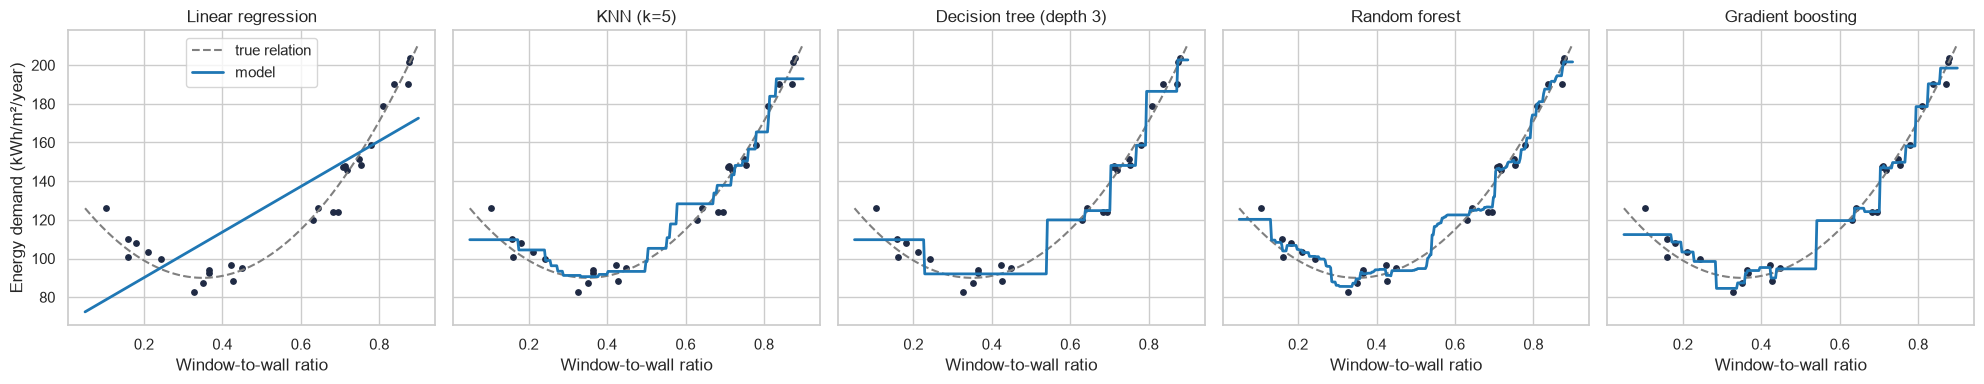

In [38]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

toy_models = {
    "Linear regression": LinearRegression(),
    "KNN (k=5)": KNeighborsRegressor(n_neighbors=5),
    "Decision tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Random forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingRegressor(min_samples_leaf=3, random_state=RANDOM_STATE),
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, (name, toy_model) in zip(axes, toy_models.items()):
    toy_model.fit(wwr_train.reshape(-1, 1), dem_train)
    ax.scatter(wwr_train, dem_train, color="#1f2a44", s=15)
    ax.plot(grid, true_demand(grid), color="grey", linestyle="--", label="true relation")
    ax.plot(grid, toy_model.predict(grid.reshape(-1, 1)), color="tab:blue", linewidth=2, label="model")
    ax.set_title(name)
    ax.set_xlabel("Window-to-wall ratio")
axes[0].set_ylabel("Energy demand (kWh/m²/year)")
axes[0].legend(loc="upper center")
plt.tight_layout()
save_fig("01_model_families")
plt.show()

Look at the **shape** of each prediction:
- **Linear**: a straight line. It cannot follow the curve (underfitting).
- **KNN**: follows the local average of the neighbours; a bit jumpy.
- **Decision tree**: **steps** (each leaf predicts one constant value).
- **Random forest**: many steps averaged → a smoother staircase.
- **Gradient boosting**: also step-like, built by successive corrections.

Note also what the tree-based models do at the **edges**: beyond the last training point they stay flat. They cannot extrapolate, which matters for affordability, a value that keeps drifting to new levels.

### Which model when? A cheat sheet

| Model | Data size | Non-linear relations | Interpretability | Training speed | Needs scaling | Handles missing values | Typical use |
|---|---|---|---|---|---|---|---|
| **Linear / Ridge / Logistic** | Small to huge | No (unless engineered) | **High** | **Very fast** | Yes | No | First baseline, explaining effects ("+1% price growth adds X") |
| **KNN** | Small / medium | Yes | Medium (similar examples) | No training, slow predictions | **Yes** | No | "Find the most similar past situations" |
| **Decision tree** | Small / medium | Yes | **High** (a flowchart) | Fast | No | Partly | Rules, communicating with non-experts |
| **Random forest** | Medium / large | Yes | Low (feature importance) | Medium | No | No | Robust default for tabular data |
| **Gradient boosting** | Medium / large | Yes | Low (feature importance) | Fast (Hist version) | No | **Yes** | Best accuracy on tabular data |
| **Neural networks** | Large | Yes | Very low | Slow | Yes | No | Images, point clouds, text (Day 4) |

💡 **Tip – a practical recipe:** start with a **baseline**, then a **linear model** (fast, interpretable), then a **tree ensemble** (random forest or gradient boosting). Only go further if the gain is worth the extra complexity.

# 4. Part A – Regression: forecasting next year's housing affordability

**Use case:** a **housing policy analyst** (a ministry, a central bank, a city's housing department) wants an early estimate of **next year's affordability** in each country, from the indicators known at the end of this year. It helps decide where to prepare measures (social housing programmes, lending rules) before the next statistics are published.

**Which mistake is costly?** Under-estimating a **deterioration** (predicting stable affordability when it gets much worse) means measures come too late. Large errors are therefore worse than small ones, and we watch **RMSE** next to **MAE**.

**What is known at prediction time?** Everything about **this** year and earlier (affordability, prices, incomes, lags, region, decade). Nothing about next year: that is why `affordability_next` and anything computed from it are excluded (1.5).

We already have everything we need: the time-based split (1.1), the target (log10 of next year's affordability), the time-based folds (1.3), the baselines (1.4) and the preprocessing (2.4–2.6).

## 4.1 Regression metrics: how do we measure the error?

| Metric | In words | Units | Good value | Notes |
|---|---|---|---|---|
| **MAE** – Mean Absolute Error | The average size of the errors | Same as the target (index points) | Close to 0 | Easy to explain: *"on average we are off by X points"* |
| **RMSE** – Root Mean Squared Error | Like MAE, but big errors count much more (they are squared) | Same as the target | Close to 0 | Use when **big errors are especially bad** |
| **R²** – Coefficient of determination | Share of the variation in the target that the model explains | None | 1 = perfect, 0 = as good as the baseline mean | Good for **comparing models** on the same data; can be negative for terrible models |
| **MAPE** – Mean Absolute Percentage Error | The average error as a **percentage** of the true value | % | Close to 0% | Intuitive: *"on average we are off by 4%"* |

Because we predict the **log10** of affordability, the model's raw errors are in "log units". The helper below converts predictions back to **affordability index points** before computing MAE, RMSE and MAPE.

**Main metric: MAE on log10(affordability_next)**, read as a typical **percentage** error (see below). Percentages make countries with very different index levels comparable, and the result can be compared directly with the "next year = this year" baseline.

In [39]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score


def regression_report(y_true_log, y_pred_log):
    # Compute the main regression metrics. Inputs are log10(affordability).
    # R² is computed on the log scale (what the model optimises),
    # the other metrics on real affordability index points (what humans understand).
    true_pts = 10 ** np.asarray(y_true_log)
    pred_pts = 10 ** np.asarray(y_pred_log)
    return pd.Series({
        "R² (log scale)": r2_score(y_true_log, y_pred_log),
        "MAE (index points)": mean_absolute_error(true_pts, pred_pts),
        "RMSE (index points)": root_mean_squared_error(true_pts, pred_pts),
        "MAPE (%)": mean_absolute_percentage_error(true_pts, pred_pts) * 100,
    })


# Example: the "dumb" baseline that always predicts the average log value, evaluated on the training set
regression_report(y_train, np.full(len(y_train), y_train.mean())).round(3)

R² (log scale)          0.000
MAE (index points)     31.733
RMSE (index points)    61.382
MAPE (%)               30.457
dtype: float64

The mean baseline is off by about **32 index points** and **~30%** on average on the training years. That's the "dumb" reference point; the real one is "next year = this year" (1.4).

During cross-validation we use scikit-learn's built-in **scorers**. For historical reasons, error scorers are **negative** (`neg_mean_absolute_error`), because scikit-learn always assumes "bigger is better". We flip the sign back when we show them.

The MAE on the log10 scale has a neat interpretation: an error of `0.02` in log10 means a factor of `10^0.02 = 1.047`, i.e. **about 4.7% too high or too low**.

## 4.2 Comparing models with cross-validation

We write a helper that cross-validates a dictionary of pipelines and collects the mean and standard deviation of each metric, plus the training time. All models use the **same** time-based folds from 1.3.

In [40]:
def compare_models(pipelines, X, y, cv, scoring):
    # Cross-validate every pipeline and return one row of results per model.
    #   scoring: dict {display name: scikit-learn scorer name}
    results = []
    for name, pipeline in pipelines.items():
        start = time.time()
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)  # n_jobs=-1: use all CPU cores
        row = {"model": name}
        for metric, scorer in scoring.items():
            scores = res[f"test_{metric}"]
            if scorer.startswith("neg_"):        # flip "negative errors" back to positive
                scores = -scores
            row[f"{metric} mean"] = scores.mean()
            row[f"{metric} std"] = scores.std()
        row["fit time (s)"] = res["fit_time"].mean()
        results.append(row)
        print(f"{name:<34} done in {time.time() - start:5.1f} s")
    return pd.DataFrame(results).set_index("model")


regression_scoring = {"R²": "r2", "MAE (log10)": "neg_mean_absolute_error", "RMSE (log10)": "neg_root_mean_squared_error"}

## 4.3 Experiment: does the encoder matter?

Before comparing model families, let's test what we said in section 2.3. We train a **linear model** and a **tree-based model**, each with three different encodings of the nominal column `region`:
- **One-hot** (correct for nominal data)
- **Ordinal** (alphabetical integers: a **fake order**, like `LabelEncoder`)
- **Target** encoding

In [41]:
from sklearn.linear_model import Ridge

encoders = {
    "one-hot": None,   # None = the default OneHotEncoder of our helper
    "ordinal (fake order)": OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "target": TargetEncoder(cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)),
}

encoder_pipelines = {}
for encoder_name, encoder in encoders.items():
    encoder_pipelines[f"Ridge + {encoder_name}"] = affordability_pipeline(Ridge(), nominal_encoder=encoder)
    encoder_pipelines[f"GradBoost + {encoder_name}"] = affordability_pipeline(
        HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False, nominal_encoder=encoder)

encoder_results = compare_models(encoder_pipelines, X_raw_train, y_train, time_folds,
                                 {"MAE (log10)": "neg_mean_absolute_error"})
encoder_results[["MAE (log10) mean", "MAE (log10) std"]].round(4)

Ridge + one-hot                    done in   1.2 s


GradBoost + one-hot                done in   1.0 s


Ridge + ordinal (fake order)       done in   0.8 s


GradBoost + ordinal (fake order)   done in   0.9 s


Ridge + target                     done in   0.9 s
GradBoost + target                 done in   0.1 s


,MAE (log10) mean,MAE (log10) std
model,,
Ridge + one-hot,0.0163,0.0029
GradBoost + one-hot,0.0239,0.0079
Ridge + ordinal (fake order),0.0161,0.0030
GradBoost + ordinal (fake order),0.0248,0.0092
Ridge + target,0.0161,0.0027
GradBoost + target,0.0240,0.0075


**Reading the results:**
- Unlike the course example (where encoding 81 cities with fake codes cost the linear model a lot), here the encoding makes **no real difference**: all differences are far below the standard deviation across folds (≈ 0.003 for Ridge, ≈ 0.008 for gradient boosting).
- The reason: `region` carries **little information** once the model knows this year's affordability and price changes. As the course puts it, *the encoding matters most for the columns that matter most*, and `region` is not one of them for this task.

We keep **one-hot** encoding, which is correct by construction.

## 4.4 The model zoo on affordability

Now the main comparison: every model family, with the **same** preprocessing, the **same** 5 time-based folds and the **same** metrics. Remember: linear models and KNN get scaling (`scale=True`), tree-based models don't. Next to the mean baseline we include the **"next year = this year"** baseline from 1.4: the real bar to clear.

In [42]:
from sklearn.neighbors import KNeighborsRegressor

regression_pipelines = {
    "Baseline (mean)": affordability_pipeline(DummyRegressor()),
    "Baseline (next year = this year)": PersistenceRegressor(),
    "Linear regression": affordability_pipeline(LinearRegression()),
    "Ridge": affordability_pipeline(Ridge(alpha=1.0)),
    "KNN (k=10)": affordability_pipeline(KNeighborsRegressor(n_neighbors=10)),
    "Decision tree": affordability_pipeline(DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE), scale=False),
    "Random forest": affordability_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                                  random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": affordability_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
}

regression_results = compare_models(regression_pipelines, X_raw_train, y_train, time_folds, regression_scoring)

# Typical % error implied by the log10 MAE (see 4.1)
regression_results["≈ typical error (%)"] = (10 ** regression_results["MAE (log10) mean"] - 1) * 100
regression_results.sort_values("MAE (log10) mean").round(4)

Baseline (mean)                    done in   0.9 s
Baseline (next year = this year)   done in   0.0 s
Linear regression                  done in   0.0 s
Ridge                              done in   0.0 s
KNN (k=10)                         done in   0.0 s
Decision tree                      done in   0.0 s


Random forest                      done in   0.5 s
Gradient boosting                  done in   0.1 s


,R² mean,R² std,MAE (log10) mean,MAE (log10) std,RMSE (log10) mean,RMSE (log10) std,fit time (s),≈ typical error (%)
model,,,,,,,,
Linear regression,0.9718,0.0101,0.0163,0.0030,0.0222,0.0043,0.0054,3.8328
Ridge,0.9721,0.0100,0.0163,0.0029,0.0220,0.0042,0.0048,3.8344
Random forest,0.9595,0.0116,0.0200,0.0043,0.0273,0.0073,0.2685,4.7188
Baseline (next year = this year),0.9584,0.0183,0.0205,0.0035,0.0265,0.0047,0.0004,4.8267
Gradient boosting,0.9407,0.0160,0.0239,0.0079,0.0347,0.0140,0.0476,5.6524
Decision tree,0.9370,0.0175,0.0267,0.0077,0.0345,0.0117,0.0049,6.3429
KNN (k=10),0.7682,0.1171,0.0450,0.0047,0.0595,0.0079,0.0046,10.9215
Baseline (mean),-0.1001,0.1161,0.1187,0.0347,0.1471,0.0449,0.0077,31.4368


**Reading the results:**
- **Every model beats the mean baseline**, but that is easy. The real bar is **"next year = this year"** (MAE ≈ 0.0205, ≈ 4.8% typical error).
- **Linear regression and Ridge win** (MAE ≈ 0.0163, ≈ 3.8%, R² ≈ 0.97). They are the only models clearly below persistence: the difference (≈ 0.004) is larger than the fold-to-fold spread (≈ 0.003). Ridge and plain linear regression are identical here: with 950 rows and 26 columns, regularisation barely matters.
- **Random forest** only ties with persistence; **gradient boosting**, a **single tree** and **KNN** are worse. Tree models predict levels they have seen in training (the "staircase" of section 3), but affordability keeps drifting to new levels. KNN also suffers from comparing country-years by distance in a 26-column space.
- So for this task the "best tabular model" (gradient boosting) is **not** the best. The model must fit the structure of the problem.

### Helping the trees: predict the **change** instead of the level

In 1.4 we suggested an idea: since "next year = this year" is already very good, let the model learn only **what persistence cannot**: the change from this year to next year. We wrap any pipeline in a small model that

1. trains on the target **`log10(affordability_next) − log10(affordability)`** (the log of next year's growth),
2. predicts that change and **adds this year's value back**.

This is not leakage: this year's affordability is known at prediction time; only the *answer* is rewritten. Trees now predict a small change around 0, which they can do well, instead of a level they may never have seen.

In [43]:
from sklearn.base import clone


class ChangeRegressor(RegressorMixin, BaseEstimator):
    """Predict log10(next year) as log10(this year) + a predicted change."""
    def __init__(self, estimator=None):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator).fit(X, y - X["log_affordability"].to_numpy())
        return self

    def predict(self, X):
        return self.estimator_.predict(X) + X["log_affordability"].to_numpy()


change_pipelines = {
    f"{name} (predicts change)": ChangeRegressor(regression_pipelines[name])
    for name in ["Ridge", "Decision tree", "Random forest", "Gradient boosting"]
}
change_results = compare_models(change_pipelines, X_raw_train, y_train, time_folds, regression_scoring)
change_results["≈ typical error (%)"] = (10 ** change_results["MAE (log10) mean"] - 1) * 100

all_regression_results = pd.concat([regression_results, change_results]).sort_values("MAE (log10) mean")
all_regression_results.round(4)

Ridge (predicts change)            done in   0.0 s
Decision tree (predicts change)    done in   0.0 s


Random forest (predicts change)    done in   0.5 s
Gradient boosting (predicts change) done in   0.1 s


,R² mean,R² std,MAE (log10) mean,MAE (log10) std,RMSE (log10) mean,RMSE (log10) std,fit time (s),≈ typical error (%)
model,,,,,,,,
Ridge (predicts change),0.9722,0.0102,0.0162,0.0029,0.0219,0.0042,0.0049,3.7910
Linear regression,0.9718,0.0101,0.0163,0.0030,0.0222,0.0043,0.0054,3.8328
Ridge,0.9721,0.0100,0.0163,0.0029,0.0220,0.0042,0.0048,3.8344
Random forest (predicts change),0.9687,0.0139,0.0171,0.0029,0.0229,0.0041,0.3091,4.0143
Gradient boosting (predicts change),0.9656,0.0126,0.0187,0.0036,0.0244,0.0044,0.0455,4.3896
Random forest,0.9595,0.0116,0.0200,0.0043,0.0273,0.0073,0.2685,4.7188
Baseline (next year = this year),0.9584,0.0183,0.0205,0.0035,0.0265,0.0047,0.0004,4.8267
Decision tree (predicts change),0.9512,0.0193,0.0205,0.0026,0.0287,0.0040,0.0052,4.8369
Gradient boosting,0.9407,0.0160,0.0239,0.0079,0.0347,0.0140,0.0476,5.6524


Figure saved to figures/day2_02_regression_model_comparison.png


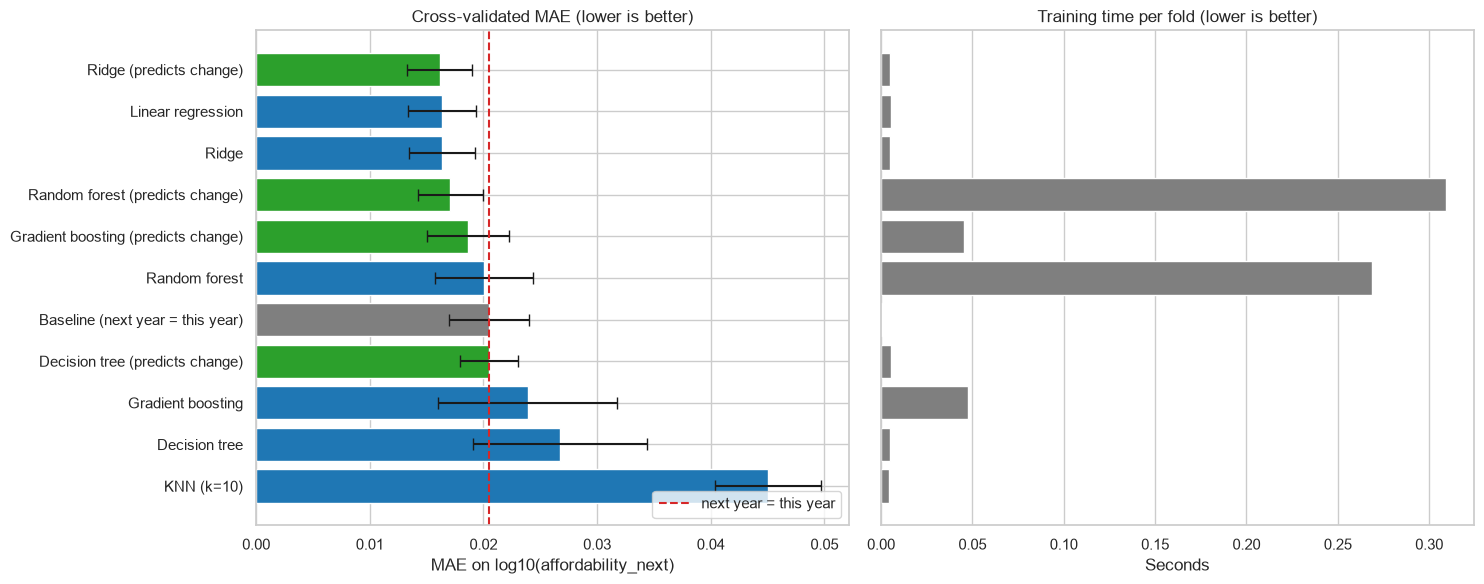

In [44]:
plot_data = all_regression_results.drop(index="Baseline (mean)").sort_values("MAE (log10) mean", ascending=False)
persistence_mae = all_regression_results.loc["Baseline (next year = this year)", "MAE (log10) mean"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# xerr = error bars of +/- one standard deviation across the 5 folds
colors = ["tab:grey" if "Baseline" in name else "tab:green" if "change" in name else "tab:blue"
          for name in plot_data.index]
axes[0].barh(plot_data.index, plot_data["MAE (log10) mean"], xerr=plot_data["MAE (log10) std"],
             color=colors, capsize=4)
axes[0].axvline(persistence_mae, color="tab:red", linestyle="--", label="next year = this year")
axes[0].set_title("Cross-validated MAE (lower is better)")
axes[0].set_xlabel("MAE on log10(affordability_next)")
axes[0].legend(loc="lower right")

axes[1].barh(plot_data.index, plot_data["fit time (s)"], color="tab:grey")
axes[1].set_title("Training time per fold (lower is better)")
axes[1].set_xlabel("Seconds")
axes[1].set_yticks([])

plt.tight_layout()
save_fig("02_regression_model_comparison")
plt.show()

**Reading the results:**
- Predicting the change helps **every tree model** a lot: gradient boosting improves from 0.0239 to 0.0187, the random forest from 0.0200 to 0.0171, and both now beat persistence. The single tree goes from clearly worse to a tie with persistence.
- For **Ridge** it changes nothing (0.0163 → 0.0162): a linear model with `log_affordability` as an input can already learn "this year's value + a correction" by itself.
- The **linear models are still the best**, and also the **fastest** (≈ 0.005 s per fold, versus ≈ 0.3 s for the random forest). Ridge vs "random forest (predicts change)" is within one standard deviation, so it is close to a tie; with equal accuracy, the faster and more interpretable model wins.

🤔 **Think about it:** the "best" model depends on your problem. Next year's affordability is mostly *this year's affordability plus a modest, fairly linear correction* (momentum in prices). A weighted sum describes that well; trees only become competitive once we give them that structure.

## 4.5 Diagnosing underfitting and overfitting: validation curves

How do we know if a model is too simple or too complex? A **validation curve** shows the training score and the cross-validation score while we turn one complexity knob. Here: the `max_depth` of a single decision tree (predicting the change).

Figure saved to figures/day2_03_validation_curve.png


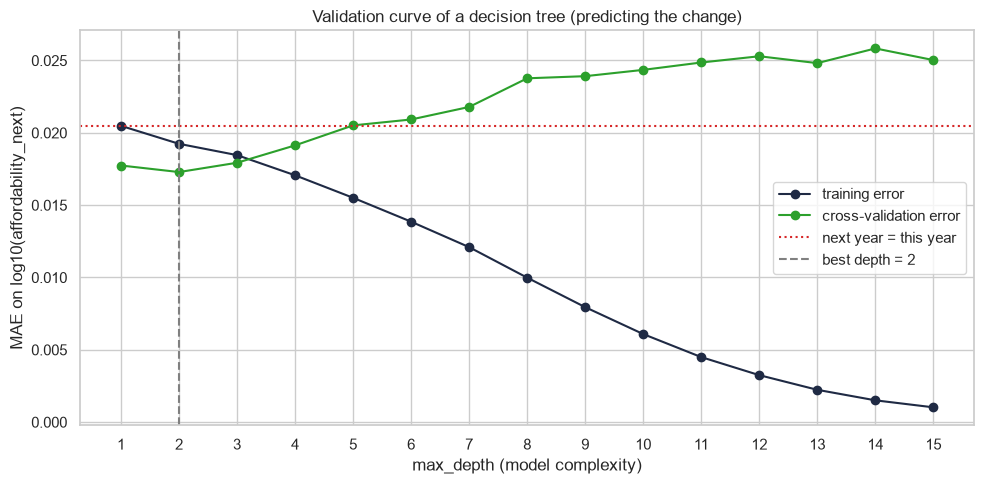

In [45]:
from sklearn.model_selection import validation_curve

depths = np.arange(1, 16)
train_scores, cv_scores = validation_curve(
    ChangeRegressor(affordability_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE), scale=False)),
    X_raw_train, y_train,
    param_name="estimator__model__max_depth",   # step names + "__" + parameter name
    param_range=depths,
    cv=time_folds, scoring="neg_mean_absolute_error", n_jobs=-1,
)
train_mae, cv_mae = -train_scores.mean(axis=1), -cv_scores.mean(axis=1)
best_tree_depth = depths[cv_mae.argmin()]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depths, train_mae, marker="o", color="#1f2a44", label="training error")
ax.plot(depths, cv_mae, marker="o", color="tab:green", label="cross-validation error")
ax.axhline(persistence_mae, color="tab:red", linestyle=":", label="next year = this year")
ax.axvline(best_tree_depth, color="grey", linestyle="--", label=f"best depth = {best_tree_depth}")
ax.set_title("Validation curve of a decision tree (predicting the change)")
ax.set_xlabel("max_depth (model complexity)")
ax.set_ylabel("MAE on log10(affordability_next)")
ax.set_xticks(depths)
ax.legend()
plt.tight_layout()
save_fig("03_validation_curve")
plt.show()

The same story as the polynomial example in 1.2, now on real data:
- **Left (depth 1–3):** training and validation errors are close together; the best validation error is at **depth 2**, a very simple tree (about 0.017, slightly better than persistence).
- **Right (deep trees):** the training error keeps falling towards 0 (the tree memorises the training years), while the validation error **rises** above the persistence line from depth 5 on → **overfitting**.
- The best depth is where the **validation** curve is lowest. The growing **gap** between the two curves is a direct measure of overfitting.

💡 **Tip:** with only 950 rows and noisy year-to-year changes, overfitting starts very early. Simple models are a good fit for small forecasting datasets.

## 4.6 Hyperparameter tuning with `GridSearchCV`

Instead of trying settings by hand, `GridSearchCV` tries **every combination** in a grid, with cross-validation, and keeps the best one. Thanks to the pipeline, parameter names are `model__<parameter>`.

We tune the two strongest candidates from 4.4:
- **Ridge:** `alpha`, the strength of the penalty on the weights.
- **Gradient boosting (predicting the change):** `learning_rate` (how strongly each new tree corrects the previous ones) and `max_leaf_nodes` (how complex each tree can be).

The test set is **still locked**: the grid search only uses the training set (with the time-based folds).

In [46]:
from sklearn.model_selection import GridSearchCV

start = time.time()
ridge_search = GridSearchCV(
    affordability_pipeline(Ridge()),
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=time_folds, scoring="neg_mean_absolute_error", n_jobs=-1,
).fit(X_raw_train, y_train)

gb_search = GridSearchCV(
    ChangeRegressor(affordability_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE), scale=False)),
    {"estimator__model__learning_rate": [0.03, 0.1],
     "estimator__model__max_leaf_nodes": [7, 15, 31],
     "estimator__model__max_iter": [200]},
    cv=time_folds, scoring="neg_mean_absolute_error", n_jobs=-1,
).fit(X_raw_train, y_train)
print(f"Both grid searches done in {time.time() - start:.0f} s\n")

for label, search, default in [
    ("Ridge", ridge_search, all_regression_results.loc["Ridge", "MAE (log10) mean"]),
    ("Gradient boosting (change)", gb_search, all_regression_results.loc["Gradient boosting (predicts change)", "MAE (log10) mean"]),
]:
    best_std = search.cv_results_["std_test_score"][search.best_index_]
    print(f"{label}: best {search.best_params_}")
    print(f"   CV MAE {-search.best_score_:.4f} ± {best_std:.4f}   (default settings: {default:.4f})")

Both grid searches done in 1 s

Ridge: best {'model__alpha': 0.1}
   CV MAE 0.0163 ± 0.0029   (default settings: 0.0163)
Gradient boosting (change): best {'estimator__model__learning_rate': 0.03, 'estimator__model__max_iter': 200, 'estimator__model__max_leaf_nodes': 7}
   CV MAE 0.0175 ± 0.0036   (default settings: 0.0187)


In [47]:
# The Ridge grid as a table
ridge_table = pd.DataFrame({
    "alpha": ridge_search.cv_results_["param_model__alpha"],
    "CV MAE mean": -ridge_search.cv_results_["mean_test_score"],
    "CV MAE std": ridge_search.cv_results_["std_test_score"],
}).set_index("alpha")
ridge_table.round(4)

,CV MAE mean,CV MAE std
alpha,,
0.01,0.0163,0.0030
0.10,0.0163,0.0029
1.00,0.0163,0.0029
10.00,0.0196,0.0048
100.00,0.0277,0.0098


**Reading the results:**
- **Ridge:** `alpha` between 0.01 and 1 gives the **same** score (0.0163); only strong penalties (10, 100) hurt. Tuning brings **no gain**: the default was already fine.
- **Gradient boosting (change):** tuning helps (0.0187 → 0.0175, smaller and more careful trees), a gain of about one standard deviation (0.0036). But it still does not beat Ridge.

Tuning usually gives a **modest** gain; good features and the right problem formulation (4.4) matter much more. `GridSearchCV` automatically re-trains the best combination on the **whole** training set; it is available as `ridge_search.best_estimator_`.

**Final model: Ridge (`alpha=0.1`).** Best cross-validated score, trains in milliseconds, and every weight can be read (4.8).

## 4.7 Final evaluation on the test set (once!)

Now, and only now, we unlock the test set (2015–2024). This is our honest estimate of how the model will perform on future years. For comparison we also score the "next year = this year" baseline on the same years.

In [48]:
best_affordability_model = ridge_search.best_estimator_   # already refit on the full training set
y_pred_test = best_affordability_model.predict(X_raw_test)

test_report = pd.DataFrame({
    "Final model (Ridge)": regression_report(y_test, y_pred_test),
    "Baseline: next year = this year": regression_report(y_test, PersistenceRegressor().predict(X_raw_test)),
})
cv_mae_final = -ridge_search.best_score_
print(f"Cross-validated MAE (log10): {cv_mae_final:.4f}   ->   test MAE (log10): "
      f"{mean_absolute_error(y_test, y_pred_test):.4f}")
test_report.round(3)

Cross-validated MAE (log10): 0.0163   ->   test MAE (log10): 0.0136


,Final model (Ridge),Baseline: next year = this year
R² (log scale),0.828,0.770
MAE (index points),3.262,3.735
RMSE (index points),4.715,5.255
MAPE (%),3.167,3.657


💡 **Tip:** compare the test score with the cross-validated score. Here the test MAE (0.0136) is even **lower** than the CV estimate (0.0163), as we saw in 1.3: 2015–2024 was calmer than the folds that include the 1980s–90s and 2008. So our validation was, if anything, cautious; we report the CV number as the realistic expectation.

On the test years the final model has a **MAPE of ≈ 3.2%** (≈ 3.3 index points), against ≈ 3.7% for "next year = this year": about **13% smaller errors** than the honest baseline, with R² 0.83 vs 0.77 on the log scale.

Numbers are important, but **plots** show *where* the model goes wrong. Two classic plots:
- **Predicted vs actual:** a perfect model puts every point on the diagonal.
- **Distribution of the errors:** in percent, so an error of 5 points on a low index and on a high one are comparable.

Figure saved to figures/day2_04_regression_test_results.png


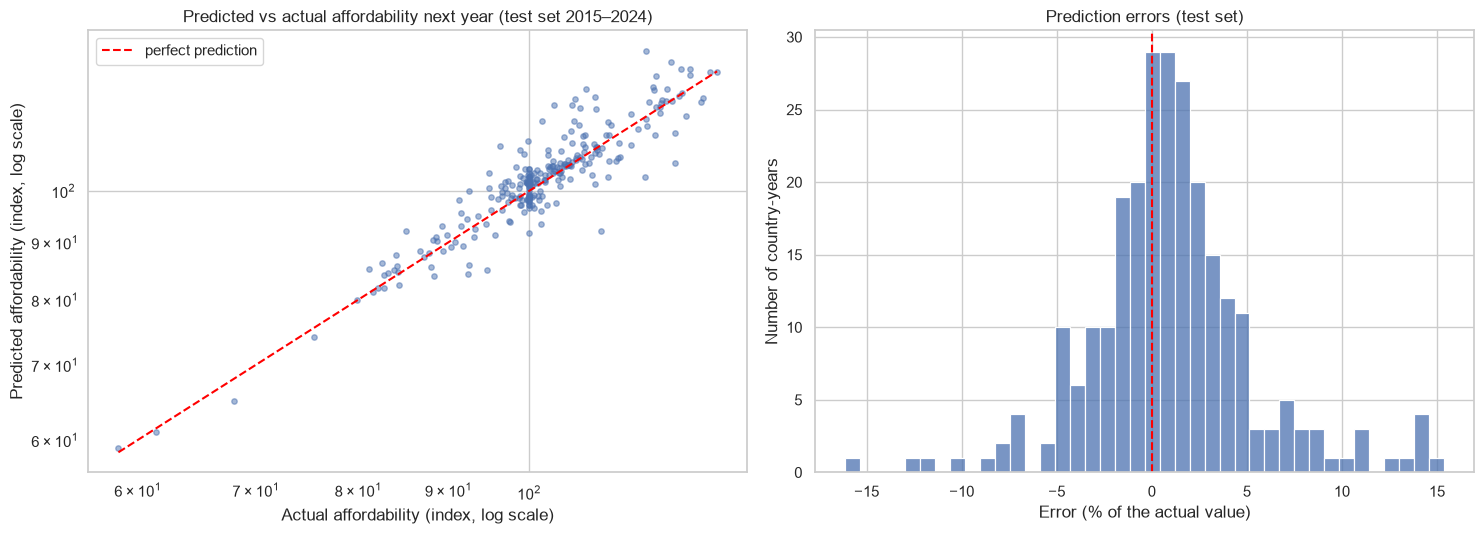

82% of the test country-years are predicted within ±5% of the actual value
Mean error: +1.0% (positive = model too high)


In [49]:
true_pts = 10 ** y_test
pred_pts = 10 ** y_pred_test
percent_error = (pred_pts - true_pts) / true_pts * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(true_pts, pred_pts, alpha=0.5, s=15)
limits = [true_pts.min(), true_pts.max()]
axes[0].plot(limits, limits, color="red", linestyle="--", label="perfect prediction")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Predicted vs actual affordability next year (test set 2015–2024)")
axes[0].set_xlabel("Actual affordability (index, log scale)")
axes[0].set_ylabel("Predicted affordability (index, log scale)")
axes[0].legend()

sns.histplot(percent_error, bins=40, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Prediction errors (test set)")
axes[1].set_xlabel("Error (% of the actual value)")
axes[1].set_ylabel("Number of country-years")

plt.tight_layout()
save_fig("04_regression_test_results")
plt.show()

within_5 = (percent_error.abs() <= 5).mean()
print(f"{within_5:.0%} of the test country-years are predicted within ±5% of the actual value")
print(f"Mean error: {percent_error.mean():+.1f}% (positive = model too high)")

Where does the model struggle? Let's compute the error **per country**:

In [50]:
errors_by_country = (
    pd.DataFrame({"country": df.loc[~is_train, "iso"], "abs_pct_error": percent_error.abs()})
    .groupby("country")["abs_pct_error"]
    .agg(["median", "max"])
    .sort_values("median")
    .rename(columns={"median": "median abs. error (%)", "max": "worst year (%)"})
)
pd.concat([errors_by_country.head(3), errors_by_country.tail(3)]).round(1)

,median abs. error (%),worst year (%)
country,,
ESP,0.8,6.9
BEL,0.9,4.4
FRA,1.1,8.4
JPN,4.1,8.2
SWE,4.1,15.4
CAN,4.7,16.1


**Reading the results:**
- **82%** of the test country-years are predicted within **±5%**, and the errors are centred close to 0 (mean +1%: the model is very slightly too high on average, i.e. slightly pessimistic).
- The easiest countries (**Spain, Belgium, France**: median error ≈ 1%) had **smooth** affordability paths in 2015–2024.
- The hardest (**Canada, Sweden, Japan**: median ≈ 4–5%, worst years ≈ 15%) had **sharp turns**: Canada's and Sweden's prices rose fast and then fell back after 2022 when interest rates went up. A model that relies on this year's level and momentum cannot see a turn coming.

🤔 **Think about it:** what does our data *not* contain? **Interest rates**, mortgage rules, housing supply and migration: the drivers of those turns (see the README limitations). The model can only extrapolate from the past of prices and incomes.

## 4.8 Interpretation: which features matter?

Two complementary views:
1. **Linear model coefficients:** for a linear model, each weight tells how much the (log) affordability next year changes when a feature increases by one unit (one standard deviation, since we scaled).
2. **Permutation importance:** works for **any** model. We randomly **shuffle** one column of the test set and measure how much the score drops. If shuffling a column destroys the performance, the model relied on it heavily.

In [51]:
# 1) Coefficients of the final Ridge model
coefficients = pd.Series(
    best_affordability_model.named_steps["model"].coef_,
    index=best_affordability_model.named_steps["preprocess"].get_feature_names_out(),
)
numeric_coefficients = coefficients[coefficients.index.str.startswith("num__")]
numeric_coefficients.index = numeric_coefficients.index.str.replace("num__", "")
numeric_coefficients.sort_values().round(4)

affordability_lag1                -0.0179
real_house_price_index            -0.0069
real_income_change_pct            -0.0037
price_shock_up                    -0.0019
gfc_period                        -0.0014
nominal_zero                       0.0000
price_shock_down                   0.0000
hyperinflation_country             0.0004
affordability_3yr_avg              0.0020
year                               0.0039
real_personal_disposable_income    0.0090
affordability                      0.0103
affordability_lag2                 0.0133
real_hpi_change_pct                0.0157
log_affordability                  0.1733
dtype: float64

Because the target is log10(affordability next year), a coefficient of `0.1` means *"one standard deviation more of this feature multiplies next year's affordability by 10^0.1 ≈ 1.26 (+26%), all other features being equal"*.

- `log_affordability` dominates (≈ 0.17): **next year is mostly this year**.
- `real_hpi_change_pct` is the largest positive correction (≈ 0.016): when real prices grew fast this year, affordability tends to worsen further next year (**momentum**).

⚠️ **Watch out:** "all other features being equal" is a strong assumption. `affordability`, `log_affordability`, `affordability_lag1`, `affordability_lag2` and `affordability_3yr_avg` are almost the same information (correlation ≈ 0.99, Day 1). The model splits their effect between them in odd ways, which is why `affordability_lag1` even gets a **negative** sign. Interpret coefficients of correlated features **together**, not one by one.

Now the permutation importance of the final model:

Figure saved to figures/day2_05_regression_feature_importance.png


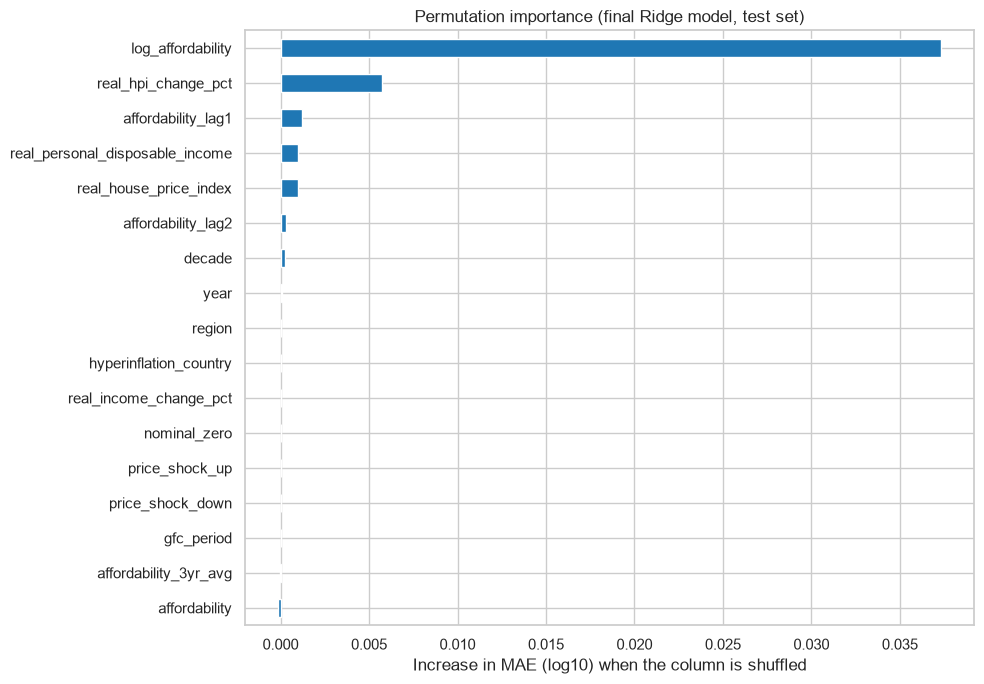

In [52]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_affordability_model, X_raw_test, y_test,
    scoring="neg_mean_absolute_error", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_affordability = pd.Series(importance.importances_mean, index=X_raw_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
importance_affordability.plot.barh(ax=ax, color="tab:blue")
ax.set_title("Permutation importance (final Ridge model, test set)")
ax.set_xlabel("Increase in MAE (log10) when the column is shuffled")
plt.tight_layout()
save_fig("05_regression_feature_importance")
plt.show()

**Reading the plot:** the model relies mostly on **this year's affordability** (`log_affordability`) and on **this year's real house price growth** (`real_hpi_change_pct`). Lags, income and the price level add a little; region, decade and the Day 1 flags add almost nothing.

⚠️ **Watch out:** importance says what the **model** uses, not what **causes** affordability. And for correlated features the importance is **shared**: shuffling `affordability` barely hurts because `log_affordability` carries the same information.

## 4.9 Save the model and use it on a new example

The pipeline contains *everything*: imputation medians, categories, encoders, scaling and the trained model. We save it to `models/model.joblib`, load it back, and use it on a **hand-made** example: a what-if scenario for Spain.

In [53]:
model_path = MODEL_DIR / "model.joblib"
joblib.dump(best_affordability_model, model_path)
print(f"Model saved to {model_path.relative_to(ROOT)} ({model_path.stat().st_size / 1e3:.0f} kB)")

# Later, or in another notebook / app:
loaded_model = joblib.load(model_path)

Model saved to models/model.joblib (6 kB)


In [54]:
# A hand-made example: Spain at the end of 2024, using its published 2024 indicators
spain_2024 = X_raw[(df["iso"] == "ESP") & (df["year"] == 2024)].copy()
forecast = 10 ** loaded_model.predict(spain_2024)[0]
print(f"Spain, affordability 2024: {spain_2024['affordability'].item():.1f}  ->  forecast for 2025: {forecast:.1f}")

# What if real house prices had risen 10% faster in 2024, with the same incomes?
# (prices up 10% -> affordability up 10%; all the price-based columns change together)
what_if = spain_2024.copy()
what_if["real_house_price_index"] *= 1.10
what_if["affordability"] *= 1.10
what_if["log_affordability"] = np.log10(what_if["affordability"])
what_if["real_hpi_change_pct"] += 10
forecast_what_if = 10 ** loaded_model.predict(what_if)[0]
print(f"Same, with a 10% stronger price rise in 2024: forecast for 2025: {forecast_what_if:.1f} "
      f"({(forecast_what_if / forecast - 1) * 100:+.1f}%)")

Spain, affordability 2024: 100.0  ->  forecast for 2025: 101.5
Same, with a 10% stronger price rise in 2024: forecast for 2025: 116.8 (+15.1%)


This is how a trained model becomes a **scenario tool**: change one input, see how the forecast moves. With its 2024 indicators, Spain's affordability is forecast to worsen slightly in 2025 (100.0 → 101.5). If real prices had risen 10% faster in 2024, the forecast rises by **≈ 15%**, more than the 10% price shock itself: the model adds **momentum** (fast price growth tends to continue), as the coefficients in 4.8 showed.

⚠️ **Watch out:** a model is only reliable for inputs **similar to its training data**. A country that is not in the dataset, or a crisis unlike anything between 1977 and 2014, would still get a prediction, but nobody should trust it blindly.

### Publishing on Hugging Face

The Day 2 assignment asks to publish this pipeline in the course organization on Hugging Face, with a **model card** (`models/README.md`). The model file `models/model.joblib` is **not** committed to GitHub (it is in `.gitignore`); it is uploaded with the `hf` command-line tool from the repository root:

```bash
hf repos create iaac-maai/day2-group8-affordability --type model --exist-ok
hf upload iaac-maai/day2-group8-affordability models . --commit-message "Upload trained pipeline and model card"
```

⚠️ Never put a Hugging Face token in this notebook: log in once with `hf auth login`.

# 5. Part B – Classification: will affordability get worse next year?

**Use case:** the same housing policy analyst sometimes does not need an exact number, only a **warning**: *will housing become **less affordable** next year (yes/no)?* A simple early-warning signal is easier to communicate than an index value.

**Which mistake is costly?** Missing a deterioration (predicting "better" when it gets "worse") means no preparation; a false alarm only costs some attention. So we care about **recall of the class "worse"**, together with an overall score.

## 5.1 A quick look at the target

We create the target from the data: **"worse"** if next year's affordability is higher than this year's (higher = less affordable), otherwise **"better"**.

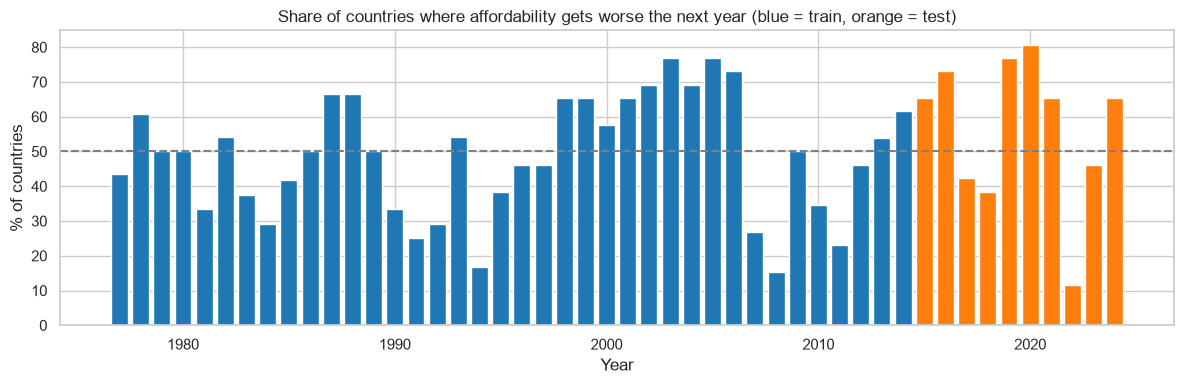

,train (%),test (%)
next_year,,
better,51.1,43.5
worse,48.9,56.5


In [55]:
y_class = pd.Series(np.where(df["affordability_next"] > df["affordability"], "worse", "better"),
                    index=df.index, name="next_year")
yc_train, yc_test = y_class[is_train], y_class[~is_train]

share_worse = (y_class == "worse").groupby(df["year"]).mean() * 100
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(share_worse.index, share_worse.values,
       color=["tab:blue" if yr < SPLIT_YEAR else "tab:orange" for yr in share_worse.index])
ax.axhline(50, color="grey", linestyle="--")
ax.set_title("Share of countries where affordability gets worse the next year (blue = train, orange = test)")
ax.set_xlabel("Year")
ax.set_ylabel("% of countries")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "train (%)": yc_train.value_counts(normalize=True).sort_index() * 100,
    "test (%)": yc_test.value_counts(normalize=True).sort_index() * 100,
}).round(1)

The two classes are close to **balanced** in the training years (49% "worse"), so accuracy is a fair first metric here. But the bars also show that the share changes a lot **over time**: whole periods where affordability worsens in most countries (late 1980s, the 1998–2006 boom, 2019–2021) and others where it improves in most (early 1990s, 2007–2011, and 2022 when interest rates rose). In the test years (2015–2024) "worse" is more common overall (57%).

⚠️ **Watch out – leakage again:** the class is computed from `affordability_next`, so it (and anything derived from it, like next year's growth in 1.5) must stay out of the inputs. We use exactly the same input columns as in Part A (`X_raw`).

## 5.2 Encoding the target

As we saw in section 2.3, `LabelEncoder` is the tool designed for **class labels**:

In [56]:
class_encoder = LabelEncoder()
y_class_codes = class_encoder.fit_transform(y_class)

print("Classes:", list(class_encoder.classes_))
print("First labels:", list(y_class[:6]), "->", [int(c) for c in y_class_codes[:6]])
print("And back:", list(class_encoder.inverse_transform([0, 1])))

Classes: ['better', 'worse']
First labels: ['better', 'worse', 'worse', 'worse', 'better', 'better'] -> [0, 1, 1, 1, 0, 0]
And back: ['better', 'worse']


💡 **Tip:** scikit-learn classifiers also accept **text labels** directly (they encode them internally) and give text back in their predictions. To keep our results readable we simply use the `"better"/"worse"` strings from now on.

## 5.3 The split: time first, stratification second

For classification, the course uses a **stratified** split (`stratify=y`): training and test sets get the same share of each class. For our data, **time comes first**: a random stratified split would leak the future (1.1). So we keep the **same time-based split and folds** as in Part A. The price: the class shares differ a little between train (49% "worse") and test (57% "worse"), because affordability worsened more often after 2015. That is the real situation a forecaster faces.

## 5.4 Classification metrics

Let's train a first model (logistic regression) and look at its errors. To evaluate without touching the test set, we use **out-of-fold** predictions: every validation year gets a prediction from the model trained on the years **before** it. (`cross_val_predict` needs every row to be validated once; with expanding time windows the first block is only used for training, so we write the small loop ourselves.)

In [57]:
from sklearn.linear_model import LogisticRegression


def out_of_fold(model, X, y, folds, method="predict"):
    # Predictions for every validation row, each from the model trained on its fold's earlier years
    idx, preds = [], []
    for train_rows, val_rows in folds:
        fitted = clone(model).fit(X.iloc[train_rows], y.iloc[train_rows])
        preds.append(getattr(fitted, method)(X.iloc[val_rows]))
        idx.extend(val_rows)
    return y.iloc[idx], np.concatenate(preds)


logistic = affordability_pipeline(LogisticRegression(max_iter=3000))
yc_val, yc_pred_oof = out_of_fold(logistic, X_raw_train, yc_train, time_folds)
print(f"{len(yc_val)} out-of-fold predictions (years 1985–2014)")

760 out-of-fold predictions (years 1985–2014)


### The confusion matrix

The most informative view of a classifier. Rows = the **true** class, columns = the **predicted** class. The **diagonal** contains the correct predictions; everything else is a mistake, and we can see exactly **which** classes get confused.

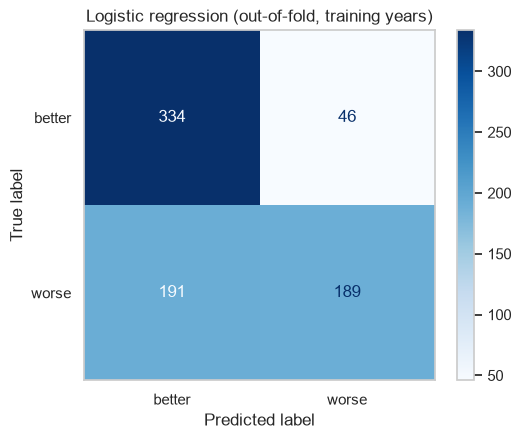

In [58]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(yc_val, yc_pred_oof, cmap="Blues", ax=ax)
ax.set_title("Logistic regression (out-of-fold, training years)")
ax.grid(False)
plt.tight_layout()
plt.show()

From the confusion matrix we derive the main metrics. For one class (say **worse**):

| Metric | Question it answers | Formula (for class "worse") |
|---|---|---|
| **Accuracy** | What share of **all** predictions is correct? | correct / total |
| **Precision** | When the model says *"worse"*, how often is it right? | true "worse" among predicted "worse" |
| **Recall** (sensitivity) | Of all the real deteriorations, how many did the model find? | true "worse" found / all real "worse" |
| **F1-score** | A single number balancing precision and recall | harmonic mean of precision and recall |

**Which one matters?** It depends on the **cost of each mistake**:
- An analyst who wants to **catch every deterioration** cares about **recall** for "worse": missing one is worse than a false alarm.
- A government that only acts on strong signals (an expensive programme) cares about **precision** for "worse": acting on a false alarm is the costly mistake.

With several classes, we average the per-class scores: the **macro** average gives every class the same weight; the **weighted** average weights each class by its size. `classification_report` shows everything at once:

In [59]:
print(classification_report(yc_val, yc_pred_oof))

              precision    recall  f1-score   support

      better       0.64      0.88      0.74       380
       worse       0.80      0.50      0.61       380

    accuracy                           0.69       760
   macro avg       0.72      0.69      0.68       760
weighted avg       0.72      0.69      0.68       760



**Reading the report:**
- Accuracy ≈ 0.69 and macro F1 ≈ 0.68: clearly better than guessing (0.5), but far from perfect. Predicting the **direction** of a small change is much harder than predicting the level (Part A).
- For **"worse"** the model is **careful**: precision 0.80 (when it warns, it is usually right) but recall only **0.50**: it **misses half** of the real deteriorations. For our use case (missing a deterioration is the costly mistake) that is the weak point. Lowering the probability threshold (see the ROC curve below) would trade some precision for more recall.

## 5.5 The accuracy trap

Accuracy looks like the obvious metric, but it can be **very misleading** when classes are **imbalanced**. Let's change the question: *"will affordability **jump** by more than 8% next year?"*. That is a sharp deterioration, and only about 9% of the country-years have one.

We compare the "dumb" baseline (always answers the most frequent class: *"no"*) with a logistic regression, and with a logistic regression told to pay more attention to the rare class (`class_weight="balanced"`):

In [60]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

jump = pd.Series(np.where(df["affordability_next"] / df["affordability"] - 1 > 0.08, "jump", "normal"),
                 index=df.index)
jump_train = jump[is_train]
print((jump_train.value_counts(normalize=True) * 100).round(1))

trap_models = {
    "Baseline (most frequent)": affordability_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": affordability_pipeline(LogisticRegression(max_iter=3000)),
    "Logistic regression (balanced)": affordability_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced")),
}

trap_rows = []
for name, model in trap_models.items():
    truth, pred = out_of_fold(model, X_raw_train, jump_train, time_folds)
    trap_rows.append({
        "model": name,
        "accuracy": accuracy_score(truth, pred),
        # pos_label: the class we care about finding
        "precision (jump)": precision_score(truth, pred, pos_label="jump", zero_division=0),
        "recall (jump)": recall_score(truth, pred, pos_label="jump"),
        "F1 (jump)": f1_score(truth, pred, pos_label="jump"),
    })
pd.DataFrame(trap_rows).set_index("model").round(3)

normal    90.6
jump       9.4
Name: proportion, dtype: float64


,accuracy,precision (jump),recall (jump),F1 (jump)
model,,,,
Baseline (most frequent),0.904,0.000,0.000,0.000
Logistic regression,0.901,0.375,0.041,0.074
Logistic regression (balanced),0.747,0.218,0.630,0.324


The baseline reaches a high accuracy of about **90%** while finding **zero** of the jumps (recall = 0). The plain logistic regression is not much better: same accuracy, but it finds only **4%** of the jumps. A report that only said *"our model is 90% accurate"* would hide a useless model.

Telling the model that the rare class matters (`class_weight="balanced"`) **lowers accuracy to 75%** but finds **63%** of the jumps: a much more useful early-warning model, at the cost of more false alarms (precision 0.22).

> **With imbalanced classes, never report accuracy alone.** Look at the confusion matrix, and at precision, recall and F1 of the class you care about.

### ROC curve and AUC (briefly)

Most classifiers output a **probability**, and we turn it into a yes/no with a **threshold** (0.5 by default). Lowering the threshold finds more positives (higher recall) but raises more false alarms. The **ROC curve** shows this trade-off for every possible threshold, and the **AUC** (area under the curve) summarises it: 0.5 = random guessing, 1.0 = perfect.

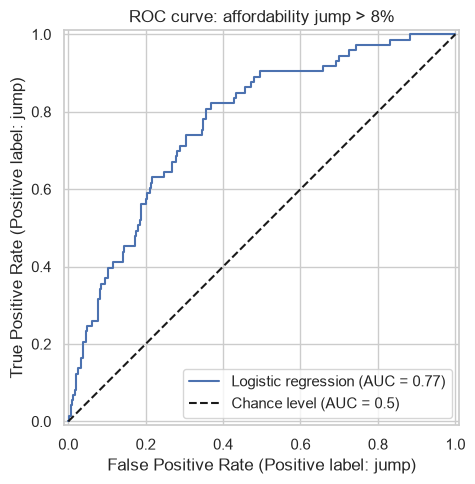

In [61]:
from sklearn.metrics import RocCurveDisplay

# method="predict_proba": out-of-fold probabilities instead of yes/no predictions
truth, proba = out_of_fold(trap_models["Logistic regression"], X_raw_train, jump_train, time_folds,
                           method="predict_proba")
proba_jump = proba[:, 0]   # columns are sorted alphabetically: ["jump", "normal"]

fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(truth, proba_jump, pos_label="jump", ax=ax,
                                 name="Logistic regression", plot_chance_level=True)
ax.set_title("ROC curve: affordability jump > 8%")
plt.tight_layout()
plt.show()

The ROC curve of the (plain) logistic regression has an **AUC ≈ 0.77**: its probabilities do rank jumps above normal years much better than chance (0.5). The problem in the table above was the **threshold** (0.5), not the ranking: with a lower threshold, many more jumps are found, as the balanced model showed.

## 5.6 The disguised categorical trap

In the course data, some categories were **stored as numbers** (e.g. orientation 2, 3, 4, 5), so a quick `select_dtypes("number")` would treat them as quantities. Let's check our own numeric columns:
- `nominal_zero`, `hyperinflation_country`, `price_shock_up`, `price_shock_down`, `gfc_period`: **0/1 flags**. A flag is safe as a number: there is only one step, from "no" to "yes".
- `year`: a real quantity (time).
- `decade` (stored as 1970, 1980, …): a **real order**, so treating it as a number or as an ordinal code is fine.

So our data has **no disguised nominal column**. The only nominal column, `region`, is text. To see the trap anyway, we compare logistic regression with `region` as **alphabetical integer codes** (a fake order, as if it had been stored as numbers) vs **one-hot encoded**:

In [62]:
classification_scoring = {"accuracy": "accuracy", "macro F1": "f1_macro"}

disguise_pipelines = {
    "region as integer codes": affordability_pipeline(
        LogisticRegression(max_iter=3000),
        nominal_encoder=OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    "region one-hot encoded": affordability_pipeline(LogisticRegression(max_iter=3000)),
}
compare_models(disguise_pipelines, X_raw_train, yc_train, time_folds, classification_scoring).round(3)

region as integer codes            done in   0.0 s
region one-hot encoded             done in   0.0 s


,accuracy mean,accuracy std,macro F1 mean,macro F1 std,fit time (s)
model,,,,,
region as integer codes,0.692,0.067,0.665,0.067,0.009
region one-hot encoded,0.687,0.065,0.658,0.072,0.009


Here the difference is tiny (0.665 vs 0.658 macro F1) and **much smaller than the standard deviation across folds** (≈ 0.07): we cannot say that one version is better. As in 4.3, `region` has little effect on next year's direction, so *how* we encode it hardly matters.

The lesson: **the encoding matters most for the columns that matter most**. We keep one-hot encoding, which is correct by construction.

💡 **Tip:** when two results differ by less than their standard deviation, treat them as a tie.

## 5.7 The model zoo on "worse next year"

The same model families, now in their **classification** versions, built with the **same** helper: pipelines work identically for regression and classification.

In [63]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

classification_pipelines = {
    "Baseline (most frequent)": affordability_pipeline(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": affordability_pipeline(LogisticRegression(max_iter=3000)),
    "KNN (k=10)": affordability_pipeline(KNeighborsClassifier(n_neighbors=10)),
    "Decision tree": affordability_pipeline(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), scale=False),
    "Random forest": affordability_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                                   random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": affordability_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
}

classification_results = compare_models(classification_pipelines, X_raw_train, yc_train,
                                        time_folds, classification_scoring)
classification_results.sort_values("macro F1 mean", ascending=False).round(3)

Baseline (most frequent)           done in   0.0 s
Logistic regression                done in   0.0 s
KNN (k=10)                         done in   0.0 s
Decision tree                      done in   0.0 s


Random forest                      done in   0.2 s
Gradient boosting                  done in   0.1 s


,accuracy mean,accuracy std,macro F1 mean,macro F1 std,fit time (s)
model,,,,,
Random forest,0.714,0.024,0.696,0.022,0.147
Logistic regression,0.687,0.065,0.658,0.072,0.008
Decision tree,0.692,0.036,0.658,0.066,0.009
Gradient boosting,0.679,0.048,0.657,0.062,0.045
KNN (k=10),0.647,0.050,0.611,0.044,0.006
Baseline (most frequent),0.501,0.092,0.331,0.040,0.006


Figure saved to figures/day2_06_classification_model_comparison.png


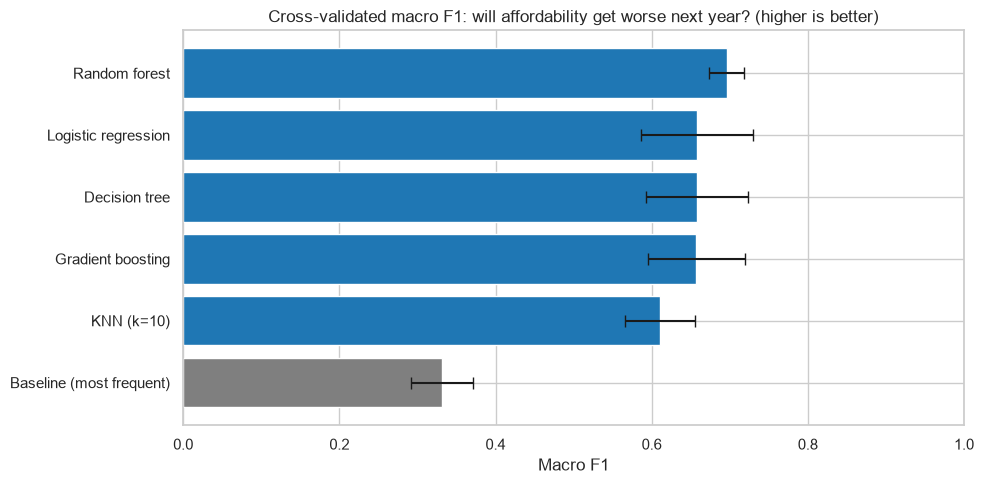

In [64]:
plot_data = classification_results.sort_values("macro F1 mean")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_data.index, plot_data["macro F1 mean"], xerr=plot_data["macro F1 std"],
        color=["tab:grey" if "Baseline" in n else "tab:blue" for n in plot_data.index], capsize=4)
ax.set_xlim(0, 1)
ax.set_title("Cross-validated macro F1: will affordability get worse next year? (higher is better)")
ax.set_xlabel("Macro F1")
plt.tight_layout()
save_fig("06_classification_model_comparison")
plt.show()

**Reading the results:**
- Every model beats the baseline (macro F1 ≈ 0.33: it always predicts the most frequent class of its training years).
- The **random forest** is best (macro F1 ≈ 0.70 ± 0.02) and also the most **stable** across folds. Logistic regression, the single tree and gradient boosting are tied around 0.66, with large standard deviations (0.06–0.07); KNN is weakest.
- The ranking is **different from Part A**, where the linear model won. Predicting the *direction* depends on thresholds and interactions (e.g. "prices still rising fast *and* affordability not yet extreme"), which trees capture and a weighted sum does not.
- Each fold contains only ~150 country-years, so differences of a few hundredths should not be over-interpreted.

🤔 **Think about it:** no model is "the best" in general (the *no free lunch* theorem): the linear model won the regression, a forest wins the classification, on the **same** inputs. That's why we always compare several.

## 5.8 A model you can read: the decision tree

A big advantage of a (small) decision tree: we can **draw** it and read it as a set of **rules**.

Figure saved to figures/day2_07_decision_tree.png


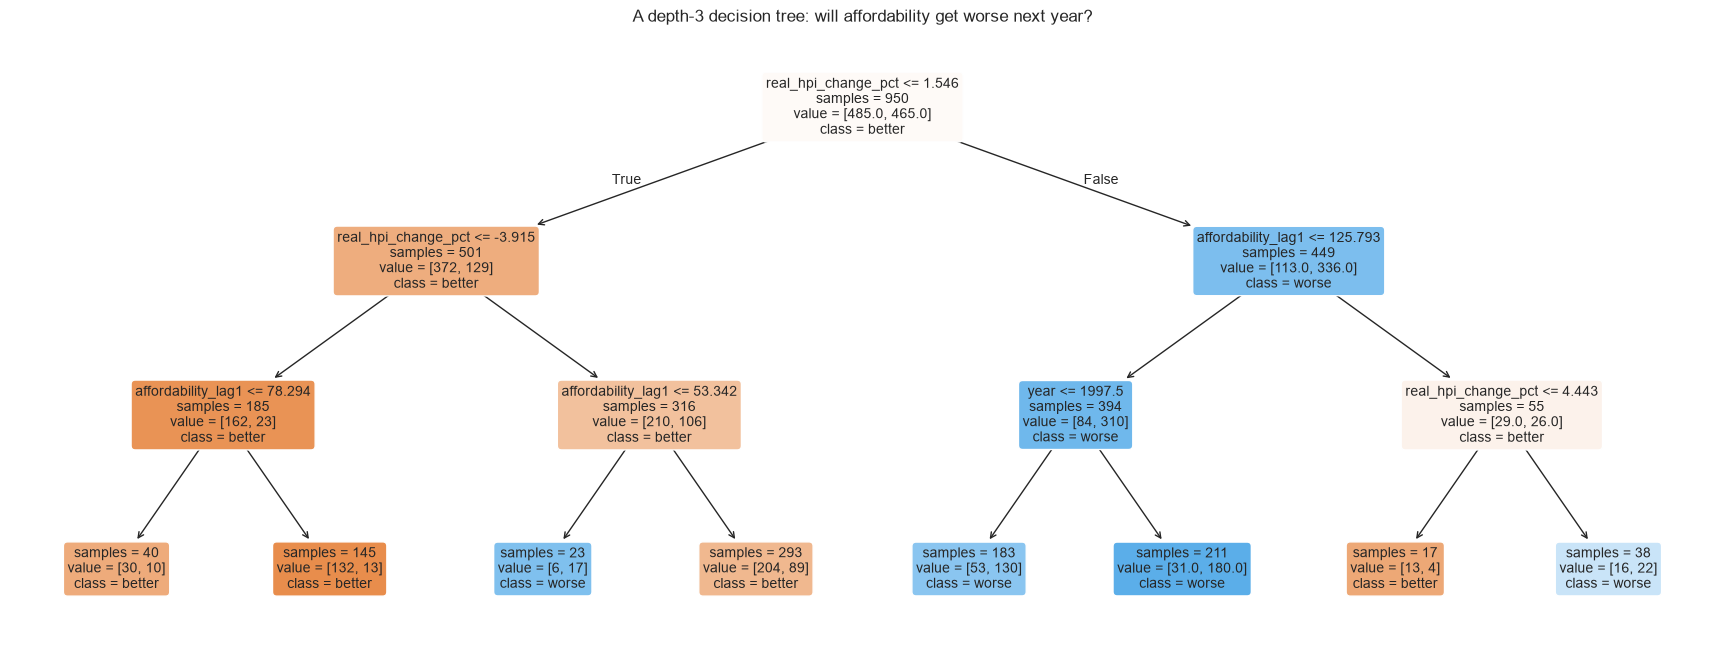

Cross-validated macro F1 of this tiny tree: 0.643 ± 0.152


In [65]:
from sklearn.tree import plot_tree

readable_tree = affordability_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE), scale=False)
readable_tree.fit(X_raw_train, yc_train)
tree_features = [n.split("__", 1)[1] for n in readable_tree.named_steps["preprocess"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(readable_tree.named_steps["model"], feature_names=tree_features,
          class_names=list(readable_tree.named_steps["model"].classes_),
          filled=True, rounded=True, impurity=False, fontsize=10, ax=ax)
ax.set_title("A depth-3 decision tree: will affordability get worse next year?")
save_fig("07_decision_tree")
plt.show()

readable_scores = cross_validate(readable_tree, X_raw_train, yc_train, cv=time_folds, scoring="f1_macro")
print(f"Cross-validated macro F1 of this tiny tree: {readable_scores['test_score'].mean():.3f} "
      f"± {readable_scores['test_score'].std():.3f}")

**How to read it:** start at the top. Each box asks a question about one feature; go **left if true**, **right if false**. `samples` = number of training country-years reaching that box, `value` = how many of them are "better" and "worse", `class` = the majority class, which is the prediction. The colour shows the predicted class (orange = better, blue = worse); the paler, the more mixed.

The first question is about **this year's real house price growth**: below ≈ 1.5%, affordability mostly improves next year (372 of 501); above it, it mostly worsens (336 of 449). The next questions use last year's affordability level and the year. Written out: *"prices growing more than 1.5% a year and affordability not yet very high (lag ≤ 126) → it will probably get worse"*. That matches the **momentum** found in Part A.

This tiny tree reaches a macro F1 of ≈ 0.64 in cross-validation, close to the bigger models, but very unstable across folds (± 0.15).

## 5.9 Final evaluation on the test set

We pick the best model from the comparison (5.7), train it on the full training set, and evaluate it **once** on the test set.

Best model: Random forest

              precision    recall  f1-score   support

      better       0.70      0.59      0.64       113
       worse       0.72      0.80      0.76       147

    accuracy                           0.71       260
   macro avg       0.71      0.70      0.70       260
weighted avg       0.71      0.71      0.71       260

Figure saved to figures/day2_08_confusion_matrix.png


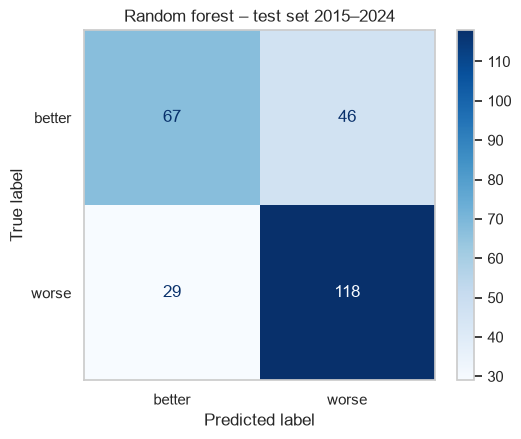

Baseline on the test set: accuracy 0.435, macro F1 0.303


In [66]:
best_name = classification_results.drop(index="Baseline (most frequent)")["macro F1 mean"].idxmax()
best_class_model = classification_pipelines[best_name].fit(X_raw_train, yc_train)
yc_pred_test = best_class_model.predict(X_raw_test)

print(f"Best model: {best_name}\n")
print(classification_report(yc_test, yc_pred_test))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred_test, cmap="Blues", ax=ax)
ax.set_title(f"{best_name} – test set 2015–2024")
ax.grid(False)
plt.tight_layout()
save_fig("08_confusion_matrix")
plt.show()

baseline_test = classification_pipelines["Baseline (most frequent)"].fit(X_raw_train, yc_train).predict(X_raw_test)
print(f"Baseline on the test set: accuracy {accuracy_score(yc_test, baseline_test):.3f}, "
      f"macro F1 {f1_score(yc_test, baseline_test, average='macro'):.3f}")

**Reading the results:**
- On the test years the random forest reaches **macro F1 ≈ 0.70** and accuracy ≈ 0.71, the same as its cross-validation score (0.70 ± 0.02): our validation process was reliable. The baseline scores 0.30 (it predicts "better", the majority of the training years, while most test years were "worse").
- For the class that matters, **"worse"**, recall is **0.80**: the model finds 4 out of 5 deteriorations, with a precision of 0.72.
- The weak spot is **"better"** (recall 0.59): it often warns of a deterioration that does not come (46 of the 113 improving country-years). For an early-warning tool, a false alarm is the cheaper mistake.

⚠️ **Watch out:** deciding the direction of a change that is often only 1–2% is genuinely hard; a 70% hit rate is a realistic result, not a failure.

## 5.10 Which indicators matter?

Permutation importance again, this time with **macro F1** as the score.

Figure saved to figures/day2_09_classification_feature_importance.png


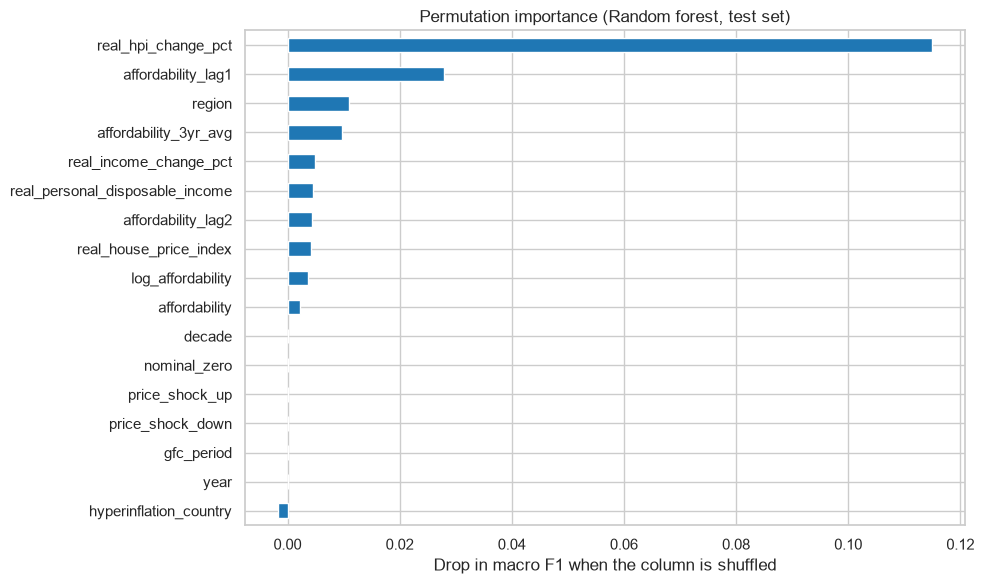

In [67]:
importance = permutation_importance(best_class_model, X_raw_test, yc_test, scoring="f1_macro",
                                    n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance_class = pd.Series(importance.importances_mean, index=X_raw_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
importance_class.plot.barh(ax=ax, color="tab:blue")
ax.set_title(f"Permutation importance ({best_name}, test set)")
ax.set_xlabel("Drop in macro F1 when the column is shuffled")
plt.tight_layout()
save_fig("09_classification_feature_importance")
plt.show()

**This year's real house price growth** (`real_hpi_change_pct`) dominates by far, followed by last year's affordability. Region, the 3-year average, income growth and the price level add a little; the Day 1 flags, `year` and `decade` add nothing.

This is the same story as Part A, told by a different model: **momentum**. Countries where real prices are rising fast this year are likely to become less affordable next year.

⚠️ **Watch out:** a low permutation importance means *"the model doesn't need this column, given the other columns"*. It does **not** mean *"this has no effect on affordability"*. Income growth surely matters for affordability; the model simply gets most of that information from the affordability columns.

# 6. Summary: which model, which metric?

### Which model?

| Situation | Good first choice | Why |
|---|---|---|
| Any new problem | **Baseline** (`Dummy…`) | Know the score to beat |
| Forecasting a slowly moving series | **Persistence baseline** ("next year = this year") | Often very hard to beat; the real bar |
| Need to explain the effect of each variable | **Linear / logistic regression** | Each weight has a meaning |
| Need rules a client or a colleague can read | **Small decision tree** | It's a flowchart |
| Tabular data, best accuracy | **Gradient boosting** (or random forest) | State of the art for tables, but cannot extrapolate |
| Missing values you don't want to impute | **`HistGradientBoosting…`** | Handles NaN natively |
| "Find similar past situations" | **KNN** | Prediction = similar examples |
| Images, point clouds, text | **Neural networks** | Day 4 |

### Which metric?

| Problem | Metric | Use it when… |
|---|---|---|
| Regression | **MAE** | You want an error in real units that anyone understands |
| Regression | **RMSE** | Large errors are especially costly |
| Regression | **R²** | Comparing models on the same data |
| Regression | **MAPE** | Values span a wide range and relative errors matter |
| Classification | **Accuracy** | Classes are balanced and all errors cost the same |
| Classification | **Precision** | False alarms are costly |
| Classification | **Recall** | Missing a positive is costly |
| Classification | **F1 / macro F1** | You need one number that balances both, especially with imbalance |
| Classification | **Confusion matrix** | Always! It shows *which* mistakes happen |

### Checklist for an honest evaluation
- [x] Split the data **first**, lock the test set away (by **time** for time series)
- [x] Compare against a **baseline** (and the persistence baseline for forecasts)
- [x] Put all preprocessing **inside a pipeline** (no leakage)
- [x] Use **cross-validation** to compare and tune models; report mean **±** standard deviation
- [x] Check for **leakage**: a "perfect" score is a red flag
- [x] Choose metrics that match the **cost of the mistakes** in your use case
- [x] Evaluate on the test set **once**, at the end
- [x] **Interpret**: which features matter, where does the model fail?

# 7. Your turn

The course exercises use the class datasets (energy, flats). We apply the same three exercises to **our** data:

1. **Regression on another target.** Predict **next year's real house price change** (%) from the same inputs. Compare a linear regression and a random forest with cross-validation. Which metric would you report to a housing analyst, and why?
2. **Classification with an imbalanced-ish target.** Predict whether **real house prices fall next year** (about 41% of the training rows). Compare a baseline and a gradient boosting classifier with accuracy **and** F1 for the *fall* class. What does the baseline's accuracy tell you?
3. **Tuning.** Pick one model from Part B and tune one or two of its hyperparameters with `GridSearchCV`. Is the improvement larger than the standard deviation across folds? Is it worth it?

In [68]:
# 1. Regression on another target: next year's real house price change (%)
by_country = df.sort_values(["iso", "year"]).groupby("iso")
next_hpi = by_country["real_hpi_change_pct"].shift(-1)
next_is_consecutive = by_country["year"].shift(-1) == df.sort_values(["iso", "year"])["year"] + 1
y_hpi = next_hpi.where(next_is_consecutive).reindex(df.index)

# same time-based split and folds; every training year has a next year in the data
print("Training rows with a target:", y_hpi[is_train].notna().sum(), "of", is_train.sum())
y_hpi_train = y_hpi[is_train]

hpi_pipelines = {
    "Baseline (mean)": affordability_pipeline(DummyRegressor()),
    "Linear regression": affordability_pipeline(LinearRegression()),
    "Random forest": affordability_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                                  random_state=RANDOM_STATE), scale=False),
}
hpi_results = compare_models(hpi_pipelines, X_raw_train, y_hpi_train, time_folds,
                             {"MAE (pp)": "neg_mean_absolute_error", "RMSE (pp)": "neg_root_mean_squared_error", "R²": "r2"})
hpi_results.round(3)

Training rows with a target: 950 of 950
Baseline (mean)                    done in   0.0 s
Linear regression                  done in   0.0 s


Random forest                      done in   0.5 s


,MAE (pp) mean,MAE (pp) std,RMSE (pp) mean,RMSE (pp) std,R² mean,R² std,fit time (s)
model,,,,,,,
Baseline (mean),5.289,0.923,6.798,1.150,-0.100,0.068,0.004
Linear regression,4.300,1.210,5.618,1.413,0.255,0.163,0.005
Random forest,4.074,0.785,5.395,0.948,0.302,0.083,0.282


**Answer:**
- Both models beat the mean baseline (MAE 5.3 percentage points): the random forest reaches **MAE ≈ 4.1 pp**, linear regression ≈ 4.3 pp. The difference is within one standard deviation (≈ 0.8–1.2), so it is close to a tie.
- But R² is only **≈ 0.3**: next year's price *growth* is much harder to predict than next year's affordability *level*, which mostly equals this year's.
- **Which metric to report to a housing analyst:** the **MAE in percentage points** ("we are typically off by about 4 points of price growth"). It is in the analyst's own units and easy to compare with typical growth rates (±7 pp). R² is useful to compare models, but "0.3" says little to a non-specialist.

In [69]:
# 2. Classification: do real house prices fall next year?
fall_train = pd.Series(np.where(y_hpi_train < 0, "fall", "rise"), index=y_hpi_train.index)
print((fall_train.value_counts(normalize=True) * 100).round(1))

fall_rows = []
for name, model in {
    "Baseline (most frequent)": affordability_pipeline(DummyClassifier(strategy="most_frequent")),
    "Gradient boosting": affordability_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
}.items():
    truth, pred = out_of_fold(model, X_raw_train, fall_train, time_folds)
    fall_rows.append({"model": name,
                      "accuracy": accuracy_score(truth, pred),
                      "precision (fall)": precision_score(truth, pred, pos_label="fall", zero_division=0),
                      "recall (fall)": recall_score(truth, pred, pos_label="fall"),
                      "F1 (fall)": f1_score(truth, pred, pos_label="fall")})
pd.DataFrame(fall_rows).set_index("model").round(3)

rise    58.6
fall    41.4
Name: proportion, dtype: float64


,accuracy,precision (fall),recall (fall),F1 (fall)
model,,,,
Baseline (most frequent),0.563,0.375,0.182,0.245
Gradient boosting,0.733,0.640,0.716,0.676


**Answer:**
- About **41%** of the training years have falling real prices the next year, so the classes are moderately imbalanced.
- The baseline reaches **56% accuracy**, and an F1 for "fall" of only 0.25. Its accuracy simply reflects how often prices *rise*: it learned nothing about falls. (Its precision and recall for "fall" are not zero because in one early fold "fall" was the most frequent class, so the baseline predicted "fall" for every year of that fold.)
- Gradient boosting reaches **73% accuracy** and **F1 ≈ 0.68** for "fall" (recall 0.72): it finds most falls. The baseline's accuracy tells us that **56% is the starting point, not 0%**: a model with 60% accuracy would be almost worthless here.

In [70]:
# 3. Tuning: the random forest from Part B
rf_search = GridSearchCV(
    affordability_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), scale=False),
    {"model__min_samples_leaf": [1, 3, 10, 30], "model__max_features": ["sqrt", 0.5, 1.0]},
    cv=time_folds, scoring="f1_macro", n_jobs=-1,
).fit(X_raw_train, yc_train)

rf_table = pd.DataFrame(rf_search.cv_results_["params"])
rf_table["macro F1"] = rf_search.cv_results_["mean_test_score"]
print("Best settings:", rf_search.best_params_)
print(f"Best CV macro F1: {rf_search.best_score_:.3f} ± {rf_search.cv_results_['std_test_score'][rf_search.best_index_]:.3f}"
      f"   (Part B settings: {classification_results.loc['Random forest', 'macro F1 mean']:.3f} "
      f"± {classification_results.loc['Random forest', 'macro F1 std']:.3f})")
rf_table.pivot(index="model__min_samples_leaf", columns="model__max_features", values="macro F1").round(3)

Best settings: {'model__max_features': 0.5, 'model__min_samples_leaf': 30}
Best CV macro F1: 0.739 ± 0.023   (Part B settings: 0.696 ± 0.022)


model__max_features,0.5,1.0,sqrt
model__min_samples_leaf,,,
1,0.667,0.664,0.669
3,0.697,0.686,0.696
10,0.734,0.728,0.705
30,0.739,0.730,0.693


**Answer:**
- The best settings use **bigger leaves** (`min_samples_leaf=30`) and half of the features per split (`max_features=0.5`): **macro F1 0.739 ± 0.023** vs 0.696 ± 0.022 with the Part B settings.
- The gain (≈ 0.04) is about **twice the standard deviation**, so it is probably real: on this small, noisy dataset, forests with simpler trees generalise better (less overfitting, as in 4.5).
- **Is it worth it?** Yes: the grid takes seconds, and the gain is clear. But we found it **after** the test evaluation in 5.9, so we do **not** re-score the test set with it: choosing a model after seeing the test results would turn the test set into a validation set (1.3). In a real project this tuning belongs before 5.9.

# 8. Conclusions and next steps

### Key findings
- **Split by time, not at random.** Shuffled cross-validation looked up to ≈ 30% better than time-based cross-validation (0.030 vs 0.042 at depth 9 in 1.3), because neighbouring years of a country are almost identical. Every evaluation in this notebook uses time-ordered folds.
- **Leakage is easy to create and easy to miss.** Adding next year's growth gave a "perfect" R² of 1.000 (1.5); fitting a scaler on all data made KNN look ≈ 20% better than it is. Pipelines prevent the second kind.
- **The persistence baseline is the real bar.** "Next year = this year" already reaches R² ≈ 0.96 (CV) with a typical error of ≈ 4.8%. Many models (KNN, single tree, gradient boosting on levels) do **not** beat it.
- **Forecasting affordability (regression):** **Ridge** regression is the best and fastest model: CV MAE 0.0163 in log10 (≈ 3.8% typical error, R² ≈ 0.97). On the untouched test years 2015–2024: **MAPE ≈ 3.2%**, 82% of country-years within ±5%, about 13% smaller errors than persistence. Tree models only become competitive when they predict the **change** instead of the level.
- **What drives the forecast:** this year's affordability and this year's **real house price growth** (momentum). Region, decade and the Day 1 flags add almost nothing. The model fails most where affordability turned sharply (Canada, Sweden, Japan), because it has no information on interest rates or supply.
- **"Worse next year?" (classification):** a **random forest** is best (CV macro F1 ≈ 0.70 ± 0.02; test 0.70), and finds **80%** of the test deteriorations. Accuracy alone is misleading: for 8%+ jumps, a baseline scores 90% accuracy while finding none.

### Final models and why
- **Regression:** Ridge (`alpha=0.1`): best cross-validated error, trains in milliseconds, and every weight can be read. Saved as `models/model.joblib`.
- **Classification:** random forest: best and most stable macro F1; recall for "worse" matches the early-warning use case.

### Limitations
- **Indexes, not money:** levels cannot be compared between countries, only changes over time (README).
- **Missing drivers:** no interest rates, mortgage rules, supply or migration; the models cannot foresee turns caused by them (e.g. the 2022 rate rises).
- **National averages** hide city-level differences; mostly **high-income countries**; 2025 data may be estimated.
- **Small data:** 950 training rows and ~150 rows per fold, so differences of a few thousandths in MAE or a few hundredths in F1 are within noise.
- **Do not use** the models for countries outside the 26 in the data, for single cities, or for multi-year forecasts (they predict one year ahead).

### Next: Day 3 – unsupervised learning
Today every example came with an answer (`y`). What if we only have `X`? On Day 3 we let the algorithms find **structure by themselves**: groups of similar countries or housing markets (clustering) and compact representations of many variables (dimensionality reduction).

### References
- scikit-learn user guide: [Supervised learning](https://scikit-learn.org/stable/supervised_learning.html), [Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html), [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html), [Encoding categorical features](https://scikit-learn.org/stable/modules/preprocessing.html#encoding-categorical-features)
- scikit-learn: [Choosing the right estimator](https://scikit-learn.org/stable/machine_learning_map.html)
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.), O'Reilly. Chapters 2–7.
- Course notebook: `Day_2/docs/application_of_supervised_learning.ipynb` (AI Methods I, IAAC MaAI 2026/27).